<a href="https://colab.research.google.com/github/sharma1002ankita-dot/icici-loan-collections-sql-control-system/blob/main/Ankita_SQL_Developer_ICICI_Bank_Banking_ICICI_Bank_Loan_Repayment_and_Collection_Operations_System.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ICICI Bank Loan Repayment & Collection Operations System

## SQL Developer Colab

**Industry:** Banking  
**Role:** SQL Developer  
**Runtime:** Google Colab  
**Database:** SQLite  
**Main skills:** relational design, REST API consumption, SQL reporting, transaction integrity, workflow automation, safe database changes

ICICI Bank loan operations require an auditable view of scheduled EMIs, received payments, overdue instalments, collection follow-ups, and restructuring requests. This notebook prepares a deterministic operational Dataset and local internal API, then places the SQL Developer in charge of database design validation, API consumption, SQL controls, transactions, automation, and engineering workflows.

# How to Use This Notebook

1. Use **Runtime -> Run all** in Google Colab.
2. Wait until the setup prints **SETUP COMPLETE**.
3. Begin only after **SQL DEVELOPER WORK STARTS HERE**.
4. Edit only cells marked **SQL DEVELOPER WORKSPACE**.
5. Every activity includes an Expected Output and a validator that reports **Passed** or **Needs Review**.
6. Mutable API and transaction activities reset their practice records so the notebook can be rerun safely.

# 1. RUN THIS SETUP ONCE - DO NOT EDIT

All environment setup, Dataset generation, temporary internal API, JSON extraction, SQLite preparation, validation helpers, and the loan-control engine are prebuilt below.

## 1.1 Environment and Project Folder

In [ ]:
PRODUCT_TITLE='ICICI Bank Loan Repayment & Collection Operations System'
COMPANY='ICICI Bank'
INDUSTRY='Banking'
REVIEW_DATE_STR='2026-08-01'
EXCEPTION_ENGINE_SQL="\nDELETE FROM loan_exceptions;\nINSERT INTO loan_exceptions SELECT 'EX-MISS-'||s.loan_id||'-'||printf('%02d',s.installment_no),'MISSED_INSTALLMENT',CASE WHEN julianday('2026-08-01')-julianday(s.due_date)>30 THEN 'CRITICAL' ELSE 'HIGH' END,s.loan_id,s.installment_no,l.branch_id,l.customer_id,s.due_amount,0,'2026-08-01 06:00:00','OPEN' FROM repayment_schedule s JOIN loans l ON l.loan_id=s.loan_id LEFT JOIN(SELECT loan_id,installment_no,SUM(amount) paid FROM payments WHERE payment_status='SUCCESS' AND payment_date<='2026-08-01' GROUP BY loan_id,installment_no)p ON p.loan_id=s.loan_id AND p.installment_no=s.installment_no WHERE s.due_date<'2026-08-01' AND COALESCE(p.paid,0)=0;\nINSERT INTO loan_exceptions SELECT 'EX-AMT-'||s.loan_id||'-'||printf('%02d',s.installment_no),'PAYMENT_AMOUNT_MISMATCH','HIGH',s.loan_id,s.installment_no,l.branch_id,l.customer_id,s.due_amount,p.paid,'2026-08-01 06:00:00','OPEN' FROM repayment_schedule s JOIN loans l ON l.loan_id=s.loan_id JOIN(SELECT loan_id,installment_no,ROUND(SUM(amount),2) paid FROM payments WHERE payment_status='SUCCESS' AND payment_date<='2026-08-01' GROUP BY loan_id,installment_no)p ON p.loan_id=s.loan_id AND p.installment_no=s.installment_no WHERE s.due_date<'2026-08-01' AND ABS(p.paid-s.due_amount)>1;\nINSERT INTO loan_exceptions SELECT 'EX-LATE-'||s.loan_id||'-'||printf('%02d',s.installment_no),'LATE_PAYMENT','MEDIUM',s.loan_id,s.installment_no,l.branch_id,l.customer_id,5,julianday(p.first_date)-julianday(s.due_date),'2026-08-01 06:00:00','OPEN' FROM repayment_schedule s JOIN loans l ON l.loan_id=s.loan_id JOIN(SELECT loan_id,installment_no,MIN(payment_date) first_date FROM payments WHERE payment_status='SUCCESS' AND payment_date<='2026-08-01' GROUP BY loan_id,installment_no)p ON p.loan_id=s.loan_id AND p.installment_no=s.installment_no WHERE julianday(p.first_date)-julianday(s.due_date)>5;\nINSERT INTO loan_exceptions SELECT 'EX-DUP-'||MIN(p.payment_id),'DUPLICATE_PAYMENT_REFERENCE','CRITICAL',MIN(p.loan_id),MIN(p.installment_no),MIN(l.branch_id),MIN(l.customer_id),1,COUNT(*),'2026-08-01 06:00:00','OPEN' FROM payments p JOIN loans l ON l.loan_id=p.loan_id WHERE p.payment_status='SUCCESS' AND p.payment_date<='2026-08-01' GROUP BY p.payment_reference HAVING COUNT(*)>1;\nINSERT INTO loan_exceptions SELECT 'EX-COL-'||s.loan_id||'-'||printf('%02d',s.installment_no),'COLLECTION_FOLLOWUP_OVERDUE','HIGH',s.loan_id,s.installment_no,l.branch_id,l.customer_id,MAX(s.due_amount-COALESCE(p.paid,0),0),COALESCE(julianday('2026-08-01')-julianday(MAX(c.action_date)),999),'2026-08-01 06:00:00','OPEN' FROM repayment_schedule s JOIN loans l ON l.loan_id=s.loan_id LEFT JOIN(SELECT loan_id,installment_no,SUM(amount) paid FROM payments WHERE payment_status='SUCCESS' AND payment_date<='2026-08-01' GROUP BY loan_id,installment_no)p ON p.loan_id=s.loan_id AND p.installment_no=s.installment_no LEFT JOIN collection_actions c ON c.loan_id=s.loan_id AND c.installment_no=s.installment_no AND c.action_date<='2026-08-01' WHERE s.due_date<'2026-08-01' AND COALESCE(p.paid,0)<s.due_amount-1 GROUP BY s.loan_id,s.installment_no HAVING MAX(c.action_date) IS NULL OR julianday('2026-08-01')-julianday(MAX(c.action_date))>10;\nINSERT INTO loan_exceptions SELECT 'EX-RR-'||r.request_id,'RESTRUCTURING_REQUEST_OVERDUE','MEDIUM',r.loan_id,NULL,l.branch_id,l.customer_id,14,julianday('2026-08-01')-julianday(r.request_date),'2026-08-01 06:00:00','OPEN' FROM restructuring_requests r JOIN loans l ON l.loan_id=r.loan_id WHERE r.request_status='PENDING' AND julianday('2026-08-01')-julianday(r.request_date)>14;\n"
EXPECTED={'Q1': {'columns': ['payment_id', 'customer_name', 'branch_name', 'loan_type', 'payment_channel', 'payment_amount', 'payment_date'], 'row_count': 10, 'first_row': {'payment_id': 'PAY0002664', 'customer_name': 'Aditi Rao 171', 'branch_name': 'Pune Retail Lending 2', 'loan_type': 'HOME_LOAN', 'payment_channel': 'UPI', 'payment_amount': 698628.75, 'payment_date': '2026-01-16'}}, 'Q2': {'columns': ['branch_id', 'branch_name', 'successful_payment_count', 'total_collected_amount'], 'row_count': 22, 'first_row': {'branch_id': 'BR022', 'branch_name': 'Bhubaneswar Retail Lending 1', 'successful_payment_count': 163, 'total_collected_amount': 15343994.38}}, 'Q3': {'columns': ['loan_id', 'installment_no', 'due_date', 'due_amount', 'paid_amount', 'balance_amount', 'reconciliation_status'], 'row_count': 2940, 'first_row': {'loan_id': 'L000001', 'installment_no': 1, 'due_date': '2026-01-06', 'due_amount': 40055.37, 'paid_amount': 40055.37, 'balance_amount': 0.0, 'reconciliation_status': 'PAID'}}, 'Q4': {'columns': ['loan_id', 'installment_no', 'due_date', 'due_amount', 'branch_name'], 'row_count': 194, 'first_row': {'loan_id': 'L000060', 'installment_no': 1, 'due_date': '2026-01-05', 'due_amount': 2670.36, 'branch_name': 'Bengaluru Retail Lending 3'}}, 'Q5': {'columns': ['loan_id', 'customer_name', 'branch_name'], 'row_count': 162, 'first_row': {'loan_id': 'L000005', 'customer_name': 'Ishaan Gupta 288', 'branch_name': 'Chennai Retail Lending 2'}}, 'Q6': {'columns': ['loan_id', 'customer_name_upper', 'loan_type_short', 'days_on_book', 'max_days_overdue', 'overdue_amount', 'open_exceptions', 'delinquency_stage'], 'row_count': 40, 'first_row': {'loan_id': 'L000420', 'customer_name_upper': 'ADITI VERMA 304', 'loan_type_short': 'PERSONAL_LOA', 'days_on_book': 273, 'max_days_overdue': 208, 'overdue_amount': 9212.73, 'open_exceptions': 5, 'delinquency_stage': 'DPD_90_PLUS'}}, 'Q7': {'columns': ['branch_id', 'branch_name', 'success_rate'], 'row_count': 13, 'first_row': {'branch_id': 'BR023', 'branch_name': 'Bhubaneswar Retail Lending 2', 'success_rate': 93.91}}, 'Q8': {'columns': ['loan_id', 'customer_name', 'branch_name', 'overdue_amount', 'max_days_overdue', 'calculated_penalty', 'collection_amount'], 'row_count': 30, 'first_row': {'loan_id': 'L000084', 'customer_name': 'Rohan Agarwal 221', 'branch_name': 'Mumbai Retail Lending 2', 'overdue_amount': 1425947.31, 'max_days_overdue': 204, 'calculated_penalty': 56728.94, 'collection_amount': 1482676.25}}, 'Q9': {'columns': ['region', 'branch_id', 'branch_name', 'collected_amount', 'region_rank'], 'row_count': 24, 'first_row': {'region': 'East', 'branch_id': 'BR022', 'branch_name': 'Bhubaneswar Retail Lending 1', 'collected_amount': 15343994.38, 'region_rank': 1}}, 'Q10': {'columns': ['payment_date', 'successful_payments', 'daily_collected_amount', 'cumulative_collected_amount', 'seven_day_moving_average'], 'row_count': 211, 'first_row': {'payment_date': '2026-01-03', 'successful_payments': 3, 'daily_collected_amount': 111691.59, 'cumulative_collected_amount': 111691.59, 'seven_day_moving_average': 111691.59}}, 'Q11': {'columns': ['payment_date', 'daily_collected_amount', 'previous_day_amount', 'absolute_change', 'percentage_change'], 'row_count': 211, 'first_row': {'payment_date': '2026-01-03', 'daily_collected_amount': 111691.59, 'previous_day_amount': None, 'absolute_change': None, 'percentage_change': None}}, 'Q12': {'columns': ['loan_id', 'customer_name', 'first_payment_id', 'first_payment_date', 'latest_payment_id', 'latest_payment_date'], 'row_count': 420, 'first_row': {'loan_id': 'L000001', 'customer_name': 'Ishaan Kapoor 139', 'first_payment_id': 'PAY0000001', 'first_payment_date': '2026-01-09', 'latest_payment_id': 'PAY0000009', 'latest_payment_date': '2026-07-09'}}, 'Q13': {'columns': ['city', 'customer_id', 'customer_name', 'exception_count', 'critical_count', 'exception_rank'], 'row_count': 37, 'first_row': {'city': 'Bengaluru', 'customer_id': 'C00147', 'customer_name': 'Nisha Verma 147', 'exception_count': 12, 'critical_count': 0, 'exception_rank': 1}}, 'AUTO-REPORT': {'columns': ['loan_id', 'installment_no', 'due_date', 'customer_name', 'branch_name', 'outstanding_amount', 'days_past_due', 'delinquency_stage', 'latest_collection_action'], 'row_count': 20, 'first_row': {'loan_id': 'L000385', 'installment_no': 1, 'due_date': '2026-01-10', 'customer_name': 'Aarav Kapoor 193', 'branch_name': 'Chennai Retail Lending 2', 'outstanding_amount': 698128.75, 'days_past_due': 203, 'delinquency_stage': 'DPD_90_PLUS', 'latest_collection_action': '2026-07-08'}}}
AUTO_FLOW_TERMS=[['scheduler'], ['internal api'], ['http', 'schema'], ['raw json'], ['sqlite'], ['sql report'], ['log', 'monitor']]
GIT_TERMS=[['requirement'], ['feature branch'], ['sql'], ['test', 'validate'], ['commit'], ['push'], ['pull request', 'review'], ['merge', 'approval']]
CHANGE_TERMS=[['requirement'], ['backup', 'rollback'], ['sql', 'change'], ['test', 'development'], ['peer review'], ['deploy', 'approved'], ['monitor', 'logs'], ['roll back', 'fails']]
from __future__ import annotations
import json,math,os,random,re,shutil,sqlite3,subprocess,sys,threading,time
from datetime import date,datetime,timedelta
from http.server import BaseHTTPRequestHandler,ThreadingHTTPServer
from pathlib import Path
from urllib.parse import parse_qs,urlparse
import pandas as pd,requests
from IPython.display import display
from graphviz import Digraph
pd.set_option('display.max_columns',60); pd.set_option('display.max_rows',100); pd.set_option('display.width',180); pd.set_option('display.float_format',lambda v:f'{v:,.2f}')
BASE_DIR=Path('/content') if Path('/content').exists() else Path.cwd(); PROJECT_ROOT=BASE_DIR/'icici_bank_loan_collection_sql'
if PROJECT_ROOT.exists(): shutil.rmtree(PROJECT_ROOT)
for f in ['data/raw','data/processed','database','logs','reports']: (PROJECT_ROOT/f).mkdir(parents=True,exist_ok=True)
print('Environment ready'); print('Project root:',PROJECT_ROOT)


Environment ready
Project root: /content/icici_bank_loan_collection_sql


## 1.2 Dataset

The setup generates a deterministic banking Dataset with loan schedules, successful and failed payments, overdue instalments, duplicate payment references, collection follow-up gaps, and restructuring-review delays. Operational events are bounded by the review date so no future record influences an as-of control.

In [ ]:
SEED=20260812; REVIEW_DATE=date(2026,8,1); REVIEW_DATE_STR=REVIEW_DATE.isoformat()
def generate_domain_dataset(seed=SEED):
    rng=random.Random(seed); review_date=date(2026,8,1)
    city_region={'Mumbai':'West','Pune':'West','Delhi':'North','Jaipur':'North','Bengaluru':'South','Chennai':'South','Kolkata':'East','Bhubaneswar':'East'}
    cities=list(city_region); loan_types=['HOME_LOAN','PERSONAL_LOAN','AUTO_LOAN','BUSINESS_LOAN','EDUCATION_LOAN']
    type_rates={'HOME_LOAN':8.60,'PERSONAL_LOAN':12.75,'AUTO_LOAN':9.25,'BUSINESS_LOAN':11.40,'EDUCATION_LOAN':9.10}
    penalty_rates={'HOME_LOAN':0.00035,'PERSONAL_LOAN':0.00060,'AUTO_LOAN':0.00045,'BUSINESS_LOAN':0.00055,'EDUCATION_LOAN':0.00035}
    branches=[]; n=1
    for city in cities:
        for j in range(1,4):
            branches.append({'branch_id':f'BR{n:03d}','branch_name':f'{city} Retail Lending {j}','city':city,'region':city_region[city],'status':'ACTIVE' if n not in {8,19} else 'SERVICE_REVIEW'}); n+=1
    fn=['Aarav','Aditi','Arjun','Bhavna','Dev','Diya','Ishaan','Kavya','Manav','Meera','Neel','Nisha','Rohan','Saanvi','Tanya','Varun']; ln=['Agarwal','Bose','Chawla','Desai','Gupta','Iyer','Jain','Kapoor','Mehta','Nair','Patel','Rao','Shah','Sharma','Singh','Verma']
    customers=[]
    for i in range(1,321):
        city=rng.choice(cities); customers.append({'customer_id':f'C{i:05d}','customer_name':f'{rng.choice(fn)} {rng.choice(ln)} {i:03d}','segment':rng.choices(['SALARIED','SELF_EMPLOYED','SME_OWNER','PROFESSIONAL'],[.46,.24,.18,.12])[0],'city':city,'risk_band':rng.choices(['LOW','MEDIUM','HIGH'],[.58,.32,.10])[0],'status':rng.choices(['ACTIVE','REVIEW'],[.97,.03])[0]})
    def emi(principal,annual,months):
        r=annual/1200; return round(principal*r*(1+r)**months/((1+r)**months-1),2)
    loans=[]
    for i in range(1,421):
        cust=customers[(i*7+rng.randint(0,319))%len(customers)]; branch=rng.choice([b for b in branches if b['city']==cust['city']]); lt=rng.choices(loan_types,[.25,.30,.18,.17,.10])[0]
        principal=rng.choice([100000,150000,200000,300000,500000,750000,1000000,1500000,2500000,4000000]); principal=rng.choice([1500000,2500000,4000000,6000000,8000000]) if lt=='HOME_LOAN' else principal
        tenure=rng.choice([12,18,24,36,48,60]); rate=type_rates[lt]; disb=date(2025,7,1)+timedelta(days=rng.randint(0,180))
        loans.append({'loan_id':f'L{i:06d}','customer_id':cust['customer_id'],'branch_id':branch['branch_id'],'loan_type':lt,'principal_amount':float(principal),'annual_interest_rate':rate,'penalty_rate_daily':penalty_rates[lt],'disbursal_date':disb.isoformat(),'tenure_months':tenure,'emi_amount':emi(principal,rate,tenure),'loan_status':rng.choices(['ACTIVE','RESTRUCTURED','CLOSED'],[.89,.07,.04])[0]})
    schedules=[]
    for l in loans:
        day=5+(int(l['loan_id'][-3:])%20); e=l['emi_amount']; interest=round(e*min(.42,l['annual_interest_rate']/30),2); principal=round(e-interest,2)
        for inst in range(1,8): schedules.append({'loan_id':l['loan_id'],'installment_no':inst,'due_date':date(2026,inst,min(day,28)).isoformat(),'principal_due':principal,'interest_due':interest,'due_amount':e,'schedule_status':'DUE'})
    loan_status={l['loan_id']:l['loan_status'] for l in loans}; payments=[]; pay_no=1; success_totals={}
    for s in schedules:
        key=(s['loan_id'],s['installment_no']); due=date.fromisoformat(s['due_date']); amt=s['due_amount']; p=.10 if loan_status[s['loan_id']]=='CLOSED' else rng.random()
        scenario='ONTIME' if p<.74 else 'LATE' if p<.83 else 'UNDER' if p<.90 else 'OVER' if p<.94 else 'FAILED_ONLY' if p<.975 else 'MISSING'; total=0.0
        if scenario in {'ONTIME','LATE','UNDER','OVER'}:
            if scenario=='ONTIME': pdte=due+timedelta(days=rng.randint(-2,3)); amount=amt
            elif scenario=='LATE': pdte=due+timedelta(days=rng.randint(7,18)); amount=amt
            elif scenario=='UNDER': pdte=due+timedelta(days=rng.randint(0,10)); amount=round(amt*rng.choice([.50,.65,.75,.85]),2)
            else: pdte=due+timedelta(days=rng.randint(0,8)); amount=round(amt+rng.choice([250.,500.,750.]),2)
            pdte=min(pdte,review_date); payments.append({'payment_id':f'PAY{pay_no:07d}','loan_id':s['loan_id'],'installment_no':s['installment_no'],'payment_date':pdte.isoformat(),'amount':round(amount,2),'payment_reference':f'PAYREF{pay_no:07d}','payment_channel':rng.choices(['UPI','NACH','NEFT','CASH','CHEQUE'],[.28,.42,.12,.08,.10])[0],'payment_status':'SUCCESS'}); pay_no+=1; total+=round(amount,2)
            if rng.random()<.08:
                payments.append({'payment_id':f'PAY{pay_no:07d}','loan_id':s['loan_id'],'installment_no':s['installment_no'],'payment_date':max(date(2026,1,1),pdte-timedelta(days=rng.randint(1,4))).isoformat(),'amount':round(amt,2),'payment_reference':f'FAILREF{pay_no:07d}','payment_channel':rng.choice(['UPI','NACH','CHEQUE']),'payment_status':'FAILED'}); pay_no+=1
        elif scenario=='FAILED_ONLY':
            pdte=min(review_date,due+timedelta(days=rng.randint(0,5))); payments.append({'payment_id':f'PAY{pay_no:07d}','loan_id':s['loan_id'],'installment_no':s['installment_no'],'payment_date':pdte.isoformat(),'amount':round(amt,2),'payment_reference':f'FAILREF{pay_no:07d}','payment_channel':rng.choice(['UPI','NACH','CHEQUE']),'payment_status':'FAILED'}); pay_no+=1
        success_totals[key]=round(total,2)
    success_rows=[p for p in payments if p['payment_status']=='SUCCESS']
    for di,base in enumerate(rng.sample(success_rows,12),1):
        dup=dict(base); dup['payment_id']=f'PAYDUP{di:04d}'; dup['payment_date']=min(review_date,date.fromisoformat(base['payment_date'])+timedelta(days=1)).isoformat(); dup['amount']=round(min(500.,max(100.,base['amount']*.10)),2); payments.append(dup); key=(dup['loan_id'],dup['installment_no']); success_totals[key]=round(success_totals.get(key,0)+dup['amount'],2)
    for s in schedules:
        paid=success_totals.get((s['loan_id'],s['installment_no']),0); s['schedule_status']='PAID' if paid>=s['due_amount']-1 else 'PARTIAL' if paid>0 else 'OVERDUE'
    actions=[]; an=1
    for s in schedules:
        if s['schedule_status']=='PAID': continue
        due=date.fromisoformat(s['due_date']); days=(review_date-due).days
        if days<1 or rng.random()<.23: continue
        ad=max(due,review_date-timedelta(days=rng.randint(11,35) if rng.random()<.38 else rng.randint(0,9)))
        actions.append({'action_id':f'COL{an:06d}','loan_id':s['loan_id'],'installment_no':s['installment_no'],'action_date':ad.isoformat(),'action_type':rng.choice(['CALL','SMS','EMAIL','FIELD_VISIT','NOTICE']),'outcome':rng.choice(['CONTACTED','PROMISE_TO_PAY','NO_RESPONSE','DISPUTE','ESCALATED']),'agent_team':rng.choice(['DIGITAL_COLLECTIONS','BRANCH_COLLECTIONS','FIELD_COLLECTIONS']),'next_action_date':min(review_date,ad+timedelta(days=rng.randint(2,10))).isoformat()}); an+=1
    rr=[]
    for i,l in enumerate(rng.sample([x for x in loans if x['loan_status']!='CLOSED'],72),1):
        rd=date(2026,6,15)+timedelta(days=rng.randint(0,43)); st=rng.choices(['PENDING','APPROVED','REJECTED'],[.42,.34,.24])[0]; dd=None if st=='PENDING' else min(review_date,rd+timedelta(days=rng.randint(2,12))).isoformat()
        rr.append({'request_id':f'RR{i:05d}','loan_id':l['loan_id'],'request_date':rd.isoformat(),'reason':rng.choice(['INCOME_INTERRUPTION','MEDICAL_EXPENSE','BUSINESS_SLOWDOWN','JOB_CHANGE','CASH_FLOW_STRESS']),'requested_tenure_months':l['tenure_months']+rng.choice([6,12,18]),'request_status':st,'decision_date':dd})
    return {'branches':branches,'customers':customers,'loans':loans,'repayment_schedules':schedules,'payments':payments,'collection_actions':actions,'restructuring_requests':rr}

api_store=generate_domain_dataset(SEED)
branches=api_store['branches']; customers=api_store['customers']; loans=api_store['loans']; repayment_schedules=api_store['repayment_schedules']; payments=api_store['payments']; collection_actions=api_store['collection_actions']; restructuring_requests=api_store['restructuring_requests']
display(pd.DataFrame([{'resource':k,'records':len(v)} for k,v in api_store.items()]))
print('Dataset seed:',SEED); print('Review date:',REVIEW_DATE_STR)


,resource,records
0,branches,24
1,customers,320
2,loans,420
3,repayment_schedules,2940
4,payments,3089
5,collection_actions,291
6,restructuring_requests,72


Dataset seed: 20260812
Review date: 2026-08-01


## 1.3 Temporary Internal API

A temporary internal API is started inside the runtime. The SQL Developer consumes this provided API; building the service is outside the work scope.

In [ ]:
if 'api_server' in globals():
    try: api_server.shutdown(); api_server.server_close()
    except Exception: pass
RESOURCE_ID_FIELDS={'branches':'branch_id','customers':'customer_id','loans':'loan_id','payments':'payment_id','collection_actions':'action_id','restructuring_requests':'request_id'}; MUTABLE_RESOURCES={'payments','collection_actions'}
practice_baselines={
'PAY_API_PUT_001':{'payment_id':'PAY_API_PUT_001','loan_id':'L000001','installment_no':7,'payment_date':'2026-07-28','amount':1000.0,'payment_reference':'API-PUT-BASE','payment_channel':'UPI','payment_status':'PENDING'},
'PAY_API_DELETE_001':{'payment_id':'PAY_API_DELETE_001','loan_id':'L000002','installment_no':7,'payment_date':'2026-07-29','amount':1200.0,'payment_reference':'API-DELETE-BASE','payment_channel':'NACH','payment_status':'PENDING'},
'COL_API_PATCH_001':{'action_id':'COL_API_PATCH_001','loan_id':'L000003','installment_no':7,'action_date':'2026-07-30','action_type':'CALL','outcome':'NO_RESPONSE','agent_team':'DIGITAL_COLLECTIONS','next_action_date':'2026-08-01'}}
def _find_record(resource,rid):
    fld=RESOURCE_ID_FIELDS.get(resource); return next((r for r in api_store.get(resource,[]) if fld and str(r.get(fld))==str(rid)),None)
def reset_api_practice_record(rid):
    resource='collection_actions' if rid.startswith('COL_') else 'payments'; fld=RESOURCE_ID_FIELDS[resource]; base=json.loads(json.dumps(practice_baselines[rid])); api_store[resource]=[r for r in api_store[resource] if r[fld]!=rid]+[base]; return json.loads(json.dumps(base))
def remove_api_practice_record(rid):
    resource='collection_actions' if rid.startswith('COL_') else 'payments'; fld=RESOURCE_ID_FIELDS[resource]; api_store[resource]=[r for r in api_store[resource] if r[fld]!=rid]
class Handler(BaseHTTPRequestHandler):
    def log_message(self,*a): return
    def _send(self,s,p):
        b=json.dumps(p).encode(); self.send_response(s); self.send_header('Content-Type','application/json'); self.send_header('Content-Length',str(len(b))); self.end_headers(); self.wfile.write(b)
    def _json(self):
        n=int(self.headers.get('Content-Length','0') or 0); return json.loads(self.rfile.read(n).decode()) if n else {}
    def do_GET(self):
        u=urlparse(self.path); parts=[p for p in u.path.split('/') if p]
        if not parts: return self._send(200,{'service':'loan-collections-internal-api','status':'ok'})
        r=parts[0]
        if r not in api_store: return self._send(404,{'error':'resource not found'})
        if len(parts)==2:
            rec=_find_record(r,parts[1]); return self._send(200,rec) if rec else self._send(404,{'error':'record not found'})
        rows=json.loads(json.dumps(api_store[r])); q=parse_qs(u.query); page=max(1,int(q.get('page',['1'])[0])); limit=max(1,int(q.get('limit',['200'])[0]))
        for k,v in q.items():
            if k not in {'page','limit'}: rows=[x for x in rows if str(x.get(k))==v[0]]
        total=len(rows); st=(page-1)*limit; self._send(200,{'records':rows[st:st+limit],'page':page,'limit':limit,'total':total})
    def do_POST(self):
        r=[p for p in urlparse(self.path).path.split('/') if p]
        if len(r)!=1 or r[0] not in MUTABLE_RESOURCES: return self._send(404,{'error':'resource not found'})
        resource=r[0]; p=self._json(); fld=RESOURCE_ID_FIELDS[resource]
        if not p.get(fld): return self._send(400,{'error':fld+' required'})
        if _find_record(resource,p[fld]): return self._send(409,{'error':'duplicate id'})
        api_store[resource].append(p); self._send(201,p)
    def do_PUT(self):
        parts=[p for p in urlparse(self.path).path.split('/') if p]
        if len(parts)!=2 or parts[0] not in MUTABLE_RESOURCES: return self._send(404,{'error':'resource not found'})
        r,rid=parts; p=self._json(); fld=RESOURCE_ID_FIELDS[r]
        if not _find_record(r,rid): return self._send(404,{'error':'record not found'})
        if p.get(fld)!=rid: return self._send(400,{'error':'matching id required'})
        api_store[r]=[x for x in api_store[r] if x[fld]!=rid]+[p]; self._send(200,p)
    def do_PATCH(self):
        parts=[p for p in urlparse(self.path).path.split('/') if p]
        if len(parts)!=2 or parts[0] not in MUTABLE_RESOURCES: return self._send(404,{'error':'resource not found'})
        r,rid=parts; rec=_find_record(r,rid)
        if not rec: return self._send(404,{'error':'record not found'})
        rec.update(self._json()); self._send(200,rec)
    def do_DELETE(self):
        parts=[p for p in urlparse(self.path).path.split('/') if p]
        if len(parts)!=2 or parts[0] not in MUTABLE_RESOURCES: return self._send(404,{'error':'resource not found'})
        r,rid=parts; fld=RESOURCE_ID_FIELDS[r]
        if not _find_record(r,rid): return self._send(404,{'error':'record not found'})
        api_store[r]=[x for x in api_store[r] if x[fld]!=rid]; self._send(200,{'deleted_id':rid})
api_server=ThreadingHTTPServer(('127.0.0.1',0),Handler); threading.Thread(target=api_server.serve_forever,daemon=True).start(); API_BASE_URL=f'http://127.0.0.1:{api_server.server_port}'; print('Temporary internal API ready:',API_BASE_URL)


Temporary internal API ready: http://127.0.0.1:46309


In [ ]:
api_documentation=pd.DataFrame([
['GET','/branches','Read branch master records','200'],['GET','/customers','Read customer records','200'],['GET','/loans','Read loan accounts','200'],['GET','/repayment_schedules','Read repayment schedule rows','200'],['GET','/payments','Read payments with filters and pagination','200'],['GET','/payments/{id}','Read one payment','200 / 404'],['POST','/collection_actions','Create one collection action','201 / 400 / 409'],['PUT','/payments/{id}','Replace a complete payment record','200 / 400 / 404'],['PATCH','/collection_actions/{id}','Update selected collection-action fields','200 / 404'],['DELETE','/payments/{id}','Delete one payment record','200 / 404'],['GET','/collection_actions','Read collection-action updates','200'],['GET','/restructuring_requests','Read restructuring requests','200']],columns=['Method','Endpoint','Purpose','Expected status']); display(api_documentation)


,Method,Endpoint,Purpose,Expected status
0,GET,/branches,Read branch master records,200
1,GET,/customers,Read customer records,200
2,GET,/loans,Read loan accounts,200
3,GET,/repayment_schedules,Read repayment schedule rows,200
4,GET,/payments,Read payments with filters and pagination,200
5,GET,/payments/{id},Read one payment,200 / 404
6,POST,/collection_actions,Create one collection action,201 / 400 / 409
7,PUT,/payments/{id},Replace a complete payment record,200 / 400 / 404
8,PATCH,/collection_actions/{id},Update selected collection-action fields,200 / 404
9,DELETE,/payments/{id},Delete one payment record,200 / 404


## 1.4 API Extraction and Dataset Validation

In [ ]:
def fetch_all(resource,page_size=250):
    page=1; rows=[]
    while True:
        response=requests.get(f'{API_BASE_URL}/{resource}',params={'page':page,'limit':page_size},timeout=10); response.raise_for_status(); payload=response.json(); rows.extend(payload['records'])
        if len(rows)>=payload['total']: break
        page+=1
    (PROJECT_ROOT/'data'/'raw'/f'{resource}.json').write_text(json.dumps(rows,indent=2),encoding='utf-8'); return rows,{'resource':resource,'rows':len(rows),'status':'SUCCESS'}
ingestion_metadata=[]; extracted={}
for resource in ['branches','customers','loans','repayment_schedules','payments','collection_actions','restructuring_requests']:
    rows,meta=fetch_all(resource); extracted[resource]=rows; ingestion_metadata.append(meta)
display(pd.DataFrame(ingestion_metadata))


,resource,rows,status
0,branches,24,SUCCESS
1,customers,320,SUCCESS
2,loans,420,SUCCESS
3,repayment_schedules,2940,SUCCESS
4,payments,3089,SUCCESS
5,collection_actions,291,SUCCESS
6,restructuring_requests,72,SUCCESS


In [ ]:
DATA_CONTRACTS={'branches':['branch_id','branch_name','city','region','status'],'customers':['customer_id','customer_name','segment','city','risk_band','status'],'loans':['loan_id','customer_id','branch_id','loan_type','principal_amount','annual_interest_rate','penalty_rate_daily','disbursal_date','tenure_months','emi_amount','loan_status'],'repayment_schedules':['loan_id','installment_no','due_date','principal_due','interest_due','due_amount','schedule_status'],'payments':['payment_id','loan_id','installment_no','payment_date','amount','payment_reference','payment_channel','payment_status'],'collection_actions':['action_id','loan_id','installment_no','action_date','action_type','outcome','agent_team','next_action_date'],'restructuring_requests':['request_id','loan_id','request_date','reason','requested_tenure_months','request_status','decision_date']}
PRIMARY_KEYS={'branches':['branch_id'],'customers':['customer_id'],'loans':['loan_id'],'repayment_schedules':['loan_id','installment_no'],'payments':['payment_id'],'collection_actions':['action_id'],'restructuring_requests':['request_id']}; quality=[]
for r,req in DATA_CONTRACTS.items():
    df=pd.DataFrame(extracted[r]); missing=[c for c in req if c not in df.columns]; nulls=int(df[PRIMARY_KEYS[r]].isna().any(axis=1).sum()); dups=int(df.duplicated(PRIMARY_KEYS[r]).sum()); quality.append({'resource':r,'missing_columns':len(missing),'null_keys':nulls,'duplicate_keys':dups,'status':'Passed' if not missing and nulls==0 and dups==0 else 'Needs Review'}); (PROJECT_ROOT/'data'/'processed'/f'{r}.json').write_text(df.to_json(orient='records',indent=2),encoding='utf-8')
display(pd.DataFrame(quality))


,resource,missing_columns,null_keys,duplicate_keys,status
0,branches,0,0,0,Passed
1,customers,0,0,0,Passed
2,loans,0,0,0,Passed
3,repayment_schedules,0,0,0,Passed
4,payments,0,0,0,Passed
5,collection_actions,0,0,0,Passed
6,restructuring_requests,0,0,0,Passed


## 1.5 SQLite Database Creation

The setup creates the normalized schema, enforces foreign keys and composite relationships, applies domain constraints and practical indexes, and loads the validated Dataset.

In [ ]:
DB_PATH=PROJECT_ROOT/'database'/'icici_loan_collection.db'
if DB_PATH.exists(): DB_PATH.unlink()
conn=sqlite3.connect(DB_PATH); conn.executescript("\nPRAGMA foreign_keys=ON;\nCREATE TABLE branches(branch_id TEXT NOT NULL PRIMARY KEY,branch_name TEXT NOT NULL,city TEXT NOT NULL,region TEXT NOT NULL CHECK(region IN ('North','South','East','West')),status TEXT NOT NULL CHECK(status IN ('ACTIVE','SERVICE_REVIEW')));\nCREATE TABLE customers(customer_id TEXT NOT NULL PRIMARY KEY,customer_name TEXT NOT NULL,segment TEXT NOT NULL CHECK(segment IN ('SALARIED','SELF_EMPLOYED','SME_OWNER','PROFESSIONAL')),city TEXT NOT NULL,risk_band TEXT NOT NULL CHECK(risk_band IN ('LOW','MEDIUM','HIGH')),status TEXT NOT NULL CHECK(status IN ('ACTIVE','REVIEW')));\nCREATE TABLE loans(loan_id TEXT NOT NULL PRIMARY KEY,customer_id TEXT NOT NULL,branch_id TEXT NOT NULL,loan_type TEXT NOT NULL CHECK(loan_type IN ('HOME_LOAN','PERSONAL_LOAN','AUTO_LOAN','BUSINESS_LOAN','EDUCATION_LOAN')),principal_amount REAL NOT NULL CHECK(principal_amount>0),annual_interest_rate REAL NOT NULL CHECK(annual_interest_rate>0),penalty_rate_daily REAL NOT NULL CHECK(penalty_rate_daily>=0),disbursal_date TEXT NOT NULL,tenure_months INTEGER NOT NULL CHECK(tenure_months>0),emi_amount REAL NOT NULL CHECK(emi_amount>0),loan_status TEXT NOT NULL CHECK(loan_status IN ('ACTIVE','RESTRUCTURED','CLOSED')),FOREIGN KEY(customer_id) REFERENCES customers(customer_id),FOREIGN KEY(branch_id) REFERENCES branches(branch_id));\nCREATE TABLE repayment_schedule(loan_id TEXT NOT NULL,installment_no INTEGER NOT NULL CHECK(installment_no>0),due_date TEXT NOT NULL,principal_due REAL NOT NULL CHECK(principal_due>=0),interest_due REAL NOT NULL CHECK(interest_due>=0),due_amount REAL NOT NULL CHECK(due_amount>0),schedule_status TEXT NOT NULL CHECK(schedule_status IN ('DUE','PAID','PARTIAL','OVERDUE')),PRIMARY KEY(loan_id,installment_no),FOREIGN KEY(loan_id) REFERENCES loans(loan_id));\nCREATE TABLE payments(payment_id TEXT NOT NULL PRIMARY KEY,loan_id TEXT NOT NULL,installment_no INTEGER NOT NULL,payment_date TEXT NOT NULL,amount REAL NOT NULL CHECK(amount>0),payment_reference TEXT NOT NULL,payment_channel TEXT NOT NULL CHECK(payment_channel IN ('UPI','NACH','NEFT','CASH','CHEQUE')),payment_status TEXT NOT NULL CHECK(payment_status IN ('SUCCESS','FAILED','PENDING','REVERSED')),FOREIGN KEY(loan_id) REFERENCES loans(loan_id),FOREIGN KEY(loan_id,installment_no) REFERENCES repayment_schedule(loan_id,installment_no));\nCREATE TABLE collection_actions(action_id TEXT NOT NULL PRIMARY KEY,loan_id TEXT NOT NULL,installment_no INTEGER NOT NULL,action_date TEXT NOT NULL,action_type TEXT NOT NULL CHECK(action_type IN ('CALL','SMS','EMAIL','FIELD_VISIT','NOTICE')),outcome TEXT NOT NULL CHECK(outcome IN ('CONTACTED','PROMISE_TO_PAY','NO_RESPONSE','DISPUTE','ESCALATED')),agent_team TEXT NOT NULL CHECK(agent_team IN ('DIGITAL_COLLECTIONS','BRANCH_COLLECTIONS','FIELD_COLLECTIONS')),next_action_date TEXT,FOREIGN KEY(loan_id) REFERENCES loans(loan_id),FOREIGN KEY(loan_id,installment_no) REFERENCES repayment_schedule(loan_id,installment_no));\nCREATE TABLE restructuring_requests(request_id TEXT NOT NULL PRIMARY KEY,loan_id TEXT NOT NULL,request_date TEXT NOT NULL,reason TEXT NOT NULL,requested_tenure_months INTEGER NOT NULL CHECK(requested_tenure_months>0),request_status TEXT NOT NULL CHECK(request_status IN ('PENDING','APPROVED','REJECTED')),decision_date TEXT,FOREIGN KEY(loan_id) REFERENCES loans(loan_id));\nCREATE TABLE loan_ledger(ledger_entry_id TEXT NOT NULL PRIMARY KEY,loan_id TEXT NOT NULL,installment_no INTEGER,entry_type TEXT NOT NULL CHECK(entry_type IN ('PAYMENT_RECEIPT','PENALTY','WAIVER','MANUAL_ADJUSTMENT')),amount REAL NOT NULL CHECK(amount<>0),entry_timestamp TEXT NOT NULL,description TEXT NOT NULL,FOREIGN KEY(loan_id) REFERENCES loans(loan_id));\nCREATE TABLE loan_exceptions(exception_id TEXT NOT NULL PRIMARY KEY,exception_type TEXT NOT NULL,severity TEXT NOT NULL CHECK(severity IN ('LOW','MEDIUM','HIGH','CRITICAL')),loan_id TEXT NOT NULL,installment_no INTEGER,branch_id TEXT NOT NULL,customer_id TEXT NOT NULL,expected_value REAL,actual_value REAL,detected_at TEXT NOT NULL,resolution_status TEXT NOT NULL CHECK(resolution_status IN ('OPEN','RESOLVED')),FOREIGN KEY(loan_id) REFERENCES loans(loan_id),FOREIGN KEY(branch_id) REFERENCES branches(branch_id),FOREIGN KEY(customer_id) REFERENCES customers(customer_id));\nCREATE TABLE api_ingestion_runs(run_id TEXT NOT NULL PRIMARY KEY,endpoint TEXT NOT NULL,fetched_at TEXT NOT NULL,rows_received INTEGER NOT NULL CHECK(rows_received>=0),rows_loaded INTEGER NOT NULL CHECK(rows_loaded>=0),run_status TEXT NOT NULL CHECK(run_status IN ('SUCCESS','FAILED')),error_message TEXT);\nCREATE INDEX idx_loans_branch_status ON loans(branch_id,loan_status); CREATE INDEX idx_schedule_due_status ON repayment_schedule(due_date,schedule_status); CREATE INDEX idx_payments_loan_installment_date ON payments(loan_id,installment_no,payment_date); CREATE INDEX idx_payments_reference ON payments(payment_reference); CREATE INDEX idx_collection_loan_date ON collection_actions(loan_id,action_date); CREATE INDEX idx_restructure_status_date ON restructuring_requests(request_status,request_date); CREATE INDEX idx_exceptions_open_branch_severity ON loan_exceptions(resolution_status,branch_id,severity);\n")
mp={'branches':'branches','customers':'customers','loans':'loans','repayment_schedules':'repayment_schedule','payments':'payments','collection_actions':'collection_actions','restructuring_requests':'restructuring_requests'}
for r,t in mp.items(): pd.DataFrame(extracted[r]).to_sql(t,conn,if_exists='append',index=False)
for i,m in enumerate(ingestion_metadata,1): conn.execute('INSERT INTO api_ingestion_runs VALUES (?,?,?,?,?,?,?)',(f'ING{i:03d}','/'+m['resource'],'2026-08-01 05:30:00',m['rows'],m['rows'],'SUCCESS',None))
conn.execute("INSERT INTO loan_ledger SELECT 'LED-'||payment_id,loan_id,installment_no,'PAYMENT_RECEIPT',amount,payment_date||' 18:00:00','Successful repayment receipt' FROM payments WHERE payment_status='SUCCESS'"); conn.commit()
print('SQLite database created:',DB_PATH)
print('Foreign keys enabled:',conn.execute('PRAGMA foreign_keys').fetchone()[0]==1)
pk_tables=['branches','customers','loans','payments','collection_actions','restructuring_requests','loan_ledger','loan_exceptions','api_ingestion_runs']
pk_not_null_schema_ok=True
for table in pk_tables:
    info=conn.execute(f'PRAGMA table_info({table})').fetchall()
    pk_cols=[row for row in info if row[5]>0]
    pk_not_null_schema_ok=pk_not_null_schema_ok and bool(pk_cols) and all(row[3]==1 for row in pk_cols)
null_pk_rejected=False
try:
    conn.execute("INSERT INTO api_ingestion_runs(run_id,endpoint,fetched_at,rows_received,rows_loaded,run_status,error_message) VALUES (NULL,'/integrity-test','2026-08-01 05:31:00',0,0,'SUCCESS',NULL)")
    conn.rollback()
except sqlite3.IntegrityError:
    conn.rollback(); null_pk_rejected=True
print('Text primary keys explicitly NOT NULL:',pk_not_null_schema_ok)
print('NULL text primary-key insert rejected:',null_pk_rejected)


SQLite database created: /content/icici_bank_loan_collection_sql/database/icici_loan_collection.db
Foreign keys enabled: True
Text primary keys explicitly NOT NULL: True
NULL text primary-key insert rejected: True


## 1.6 SQL Developer Validation and Visualization Helpers

In [ ]:
ACTIVITY_IDS=['ER-1']+[f'API-Q{i}' for i in range(1,6)]+[f'Q{i}' for i in range(1,14)]+['T1','T2','AUTO-FLOW','AUTO-REPORT','AUTO-CRON','ENG-GIT','ENG-CHANGE']
activity_status={x:'Needs Review' for x in ACTIVITY_IDS}

def record_activity(activity_id,passed,detail):
    activity_status[activity_id]='Passed' if passed else 'Needs Review'
    print(f"{activity_id}: {activity_status[activity_id]} - {detail}")
    return passed

def run_query(sql):
    if not isinstance(sql,str) or not sql.strip() or 'TODO' in sql.upper(): return pd.DataFrame()
    try: return pd.read_sql_query(sql,conn)
    except Exception as exc:
        print('Query needs review:',exc); return pd.DataFrame()

def validate_sql(activity_id,sql):
    spec=EXPECTED[activity_id]
    if not isinstance(sql,str) or not sql.strip() or 'TODO' in sql.upper():
        record_activity(activity_id,False,'SQL workspace is incomplete.'); return pd.DataFrame()
    try: df=pd.read_sql_query(sql,conn)
    except Exception as exc:
        record_activity(activity_id,False,f'SQL did not execute successfully: {exc}'); return pd.DataFrame()
    columns_ok=list(df.columns)==spec['columns']; rows_ok=len(df)==spec['row_count']
    first_ok=True if spec['first_row'] is None else (len(df)>0 and all((None if pd.isna(df.iloc[0][k]) else str(df.iloc[0][k]))==(None if v is None else str(v)) for k,v in spec['first_row'].items()))
    passed=columns_ok and rows_ok and first_ok
    detail=f"columns={columns_ok}; rows={len(df)}/{spec['row_count']}; key_result={first_ok}"
    record_activity(activity_id,passed,detail); display(df); return df

def render_er_diagram(tables,relationships):
    from graphviz import Digraph
    dot=Digraph('ER',format='svg'); dot.attr(rankdir='LR',label='ICICI Bank Loan Repayment & Collection Operations - ER Diagram',labelloc='t',fontsize='18')
    for t,cols in tables.items():
        rows=[]
        for c in cols:
            tag=' [PK]' if ' PK' in (' '+c) else (' [FK]' if ' FK' in (' '+c) else '')
            rows.append(c.split()[0]+tag)
        dot.node(t,label=t+'\\n'+'\\n'.join(rows),shape='box')
    for p,pk,c,ck,card in relationships: dot.edge(p,c,label=card+'  '+pk+' -> '+ck)
    display(dot); return dot

REQUIRED_TABLE_FIELDS={
'branches':['branch_id','branch_name','city','region','status'],
'customers':['customer_id','customer_name','segment','city','risk_band','status'],
'loans':['loan_id','customer_id','branch_id','loan_type','principal_amount','annual_interest_rate','penalty_rate_daily','disbursal_date','tenure_months','emi_amount','loan_status'],
'repayment_schedule':['loan_id','installment_no','due_date','principal_due','interest_due','due_amount','schedule_status'],
'payments':['payment_id','loan_id','installment_no','payment_date','amount','payment_reference','payment_channel','payment_status'],
'collection_actions':['action_id','loan_id','installment_no','action_date','action_type','outcome','agent_team','next_action_date'],
'restructuring_requests':['request_id','loan_id','request_date','reason','requested_tenure_months','request_status','decision_date']}
REQUIRED_RELATIONSHIPS={
('customers','customer_id','loans','customer_id','1:N'),('branches','branch_id','loans','branch_id','1:N'),
('loans','loan_id','repayment_schedule','loan_id','1:N'),('loans','loan_id','payments','loan_id','1:N'),
('repayment_schedule','loan_id + installment_no','payments','loan_id + installment_no','1:N'),('loans','loan_id','collection_actions','loan_id','1:N'),
('repayment_schedule','loan_id + installment_no','collection_actions','loan_id + installment_no','1:N'),('loans','loan_id','restructuring_requests','loan_id','1:N')}

def validate_er_design(tables,relationships):
    if not isinstance(tables,dict) or not isinstance(relationships,list) or not tables:
        record_activity('ER-1',False,'ER table and relationship definitions are incomplete.'); return
    names_ok=set(tables)==set(REQUIRED_TABLE_FIELDS)
    fields_ok=names_ok and all(all(any(x.split()[0]==f for x in tables[t]) for f in fs) for t,fs in REQUIRED_TABLE_FIELDS.items())
    markers_ok=names_ok and all(any(' PK' in (' '+x) for x in tables[t]) for t in tables)
    composite_ok=names_ok and sum(' PK' in (' '+x) for x in tables['repayment_schedule'])>=2
    rel_ok=set(tuple(x) for x in relationships)==REQUIRED_RELATIONSHIPS
    passed=names_ok and fields_ok and markers_ok and composite_ok and rel_ok
    record_activity('ER-1',passed,f'tables={names_ok}; fields={fields_ok}; keys={markers_ok}; composite_key={composite_ok}; relationships={rel_ok}')
    if passed: render_er_diagram(tables,relationships)

def validate_api_q1(response):
    ok=False
    if response is not None:
        try:
            payload=response.json(); recs=payload.get('records',[]); ok=response.status_code==200 and len(recs)==5 and all(r.get('payment_status')=='SUCCESS' and r.get('payment_channel')=='UPI' for r in recs)
            display(pd.DataFrame(recs))
        except Exception: pass
    record_activity('API-Q1',ok,'HTTP 200, five records, and every record is SUCCESS via UPI.' if ok else 'Filtered GET response is missing or does not match the required filters.')

def validate_api_q2(response,expected_id):
    ok=False
    if response is not None:
        try: p=response.json(); ok=response.status_code==201 and p.get('action_id')==expected_id and p.get('loan_id')=='L000001' and p.get('installment_no')==7
        except Exception: pass
    record_activity('API-Q2',ok,'Collection action created with the required payload.' if ok else 'POST response is missing or does not match the required payload.')
    if response is not None:
        try: display(pd.DataFrame([response.json()]))
        except Exception: pass

def validate_api_q3(response,replacement):
    ok=False
    if response is not None:
        try: p=response.json(); ok=response.status_code==200 and p==replacement
        except Exception: pass
    record_activity('API-Q3',ok,'Complete payment replacement validated.' if ok else 'PUT response is missing or does not exactly match the complete replacement payload.')
    if response is not None:
        try: display(pd.DataFrame([response.json()]))
        except Exception: pass

def validate_api_q4(response,before,patch):
    ok=False
    if response is not None and isinstance(before,dict):
        try:
            p=response.json(); targeted=all(p.get(k)==v for k,v in patch.items()); untouched=all(p.get(k)==v for k,v in before.items() if k not in patch); ok=response.status_code==200 and targeted and untouched
        except Exception: pass
    record_activity('API-Q4',ok,'Targeted collection-action fields changed and untargeted fields were preserved.' if ok else 'PATCH response is missing or changed fields outside the requested update.')
    if response is not None:
        try: display(pd.DataFrame([response.json()]))
        except Exception: pass

def validate_api_q5(before_response,delete_response,after_response):
    seq=[getattr(before_response,'status_code',None),getattr(delete_response,'status_code',None),getattr(after_response,'status_code',None)]; ok=seq==[200,200,404]
    record_activity('API-Q5',ok,f'status sequence={seq}; expected=[200, 200, 404]')

def validate_transaction(activity_id,script,ledger_id,should_exist):
    conn.execute('DELETE FROM loan_ledger WHERE ledger_entry_id=?',(ledger_id,)); conn.commit()
    if not isinstance(script,str) or not script.strip() or 'TODO' in script.upper():
        record_activity(activity_id,False,'Transaction script is incomplete; persistence has not been validated.'); return
    try: conn.executescript(script)
    except Exception as exc:
        try: conn.rollback()
        except Exception: pass
        record_activity(activity_id,False,f'Transaction script did not execute successfully: {exc}'); return
    present=conn.execute('SELECT COUNT(*) FROM loan_ledger WHERE ledger_entry_id=?',(ledger_id,)).fetchone()[0]>0; ok=present==should_exist
    record_activity(activity_id,ok,f'transaction persistence behavior validated; actual row present: {present}' if ok else f'transaction persistence did not match expectation; actual row present: {present}')
    display(pd.read_sql_query('SELECT * FROM loan_ledger WHERE ledger_entry_id=?',conn,params=(ledger_id,)))

def render_flow(title,steps):
    from graphviz import Digraph
    dot=Digraph(format='svg'); dot.attr(rankdir='LR',label=title,labelloc='t',fontsize='18')
    for i,s in enumerate(steps): dot.node(str(i),s,shape='box')
    for i in range(len(steps)-1): dot.edge(str(i),str(i+1))
    display(dot); return dot

def validate_sequence(activity_id,steps,required_terms,title):
    ok=isinstance(steps,list) and len(steps)==len(required_terms)
    if ok:
        for step,terms in zip(steps,required_terms):
            text=str(step).lower(); ok=ok and all(term in text for term in terms)
    if ok:
        record_activity(activity_id,True,f'exact {len(required_terms)}-step sequence and required concepts validated.'); render_flow(title,steps)
    else: record_activity(activity_id,False,f'Provide exactly {len(required_terms)} ordered steps with the required concepts.')

CRON_EXPECTED={'three_times_daily':'0 8,12,16 * * *','weekday_5pm':'0 17 * * 1-5','daily_midnight':'0 0 * * *','sunday_2am':'0 2 * * 0'}
def validate_cron(values):
    ok=isinstance(values,dict) and set(values)==set(CRON_EXPECTED) and all(isinstance(values[k],str) and len(values[k].split())==5 and values[k]==v for k,v in CRON_EXPECTED.items())
    record_activity('AUTO-CRON',ok,'all four exact cron expressions validated.' if ok else 'one or more cron expressions are blank, malformed, or do not match the required schedule.')
    display(pd.DataFrame([{'scenario':k,'expression':values.get(k,'') if isinstance(values,dict) else '', 'status':'Passed' if isinstance(values,dict) and values.get(k)==v else 'Needs Review'} for k,v in CRON_EXPECTED.items()]))

def progress_check():
    df=pd.DataFrame([{'activity_id':x,'status':activity_status[x]} for x in ACTIVITY_IDS]); display(df); passed=sum(v=='Passed' for v in activity_status.values()); print(f'Passed activities: {passed}/{len(ACTIVITY_IDS)}'); return df


## 1.7 Business Control Engine

The engine creates six operational exception categories for missed instalments, amount mismatches, late payments, duplicate payment references, overdue collection follow-up, and overdue restructuring review.

In [ ]:
conn.execute('DELETE FROM loan_exceptions'); conn.executescript(EXCEPTION_ENGINE_SQL); conn.commit()
exception_summary=pd.read_sql_query('SELECT exception_type,severity,COUNT(*) AS exception_count FROM loan_exceptions GROUP BY exception_type,severity ORDER BY severity,exception_type',conn); display(exception_summary)


,exception_type,severity,exception_count
0,DUPLICATE_PAYMENT_REFERENCE,CRITICAL,12
1,MISSED_INSTALLMENT,CRITICAL,167
2,COLLECTION_FOLLOWUP_OVERDUE,HIGH,196
3,MISSED_INSTALLMENT,HIGH,27
4,PAYMENT_AMOUNT_MISMATCH,HIGH,297
5,LATE_PAYMENT,MEDIUM,381
6,RESTRUCTURING_REQUEST_OVERDUE,MEDIUM,25


In [ ]:
row_counts=pd.DataFrame([{'table':t,'rows':conn.execute('SELECT COUNT(*) FROM '+t).fetchone()[0]} for t in ['branches','customers','loans','repayment_schedule','payments','collection_actions','restructuring_requests','loan_ledger','loan_exceptions','api_ingestion_runs']]); display(row_counts)
print('Review date:',REVIEW_DATE)
print('SETUP COMPLETE')
print('Next: SQL DEVELOPER WORK STARTS HERE')


,table,rows
0,branches,24
1,customers,320
2,loans,420
3,repayment_schedule,2940
4,payments,3089
5,collection_actions,291
6,restructuring_requests,72
7,loan_ledger,2758
8,loan_exceptions,1105
9,api_ingestion_runs,7


Review date: 2026-08-01
SETUP COMPLETE
Next: SQL DEVELOPER WORK STARTS HERE


# SQL DEVELOPER WORK STARTS HERE

Complete only the SQL Developer workspaces below. Existing validation calls and expected-output guidance should remain unchanged.

# 2. Database Design and ER Visualization

Define the seven required core tables and eight relationships in Python structures. `dbdiagram.io` may be used only as an optional planning aid; the validated Colab structures are the implementation source and the diagram is rendered automatically.

ER-1: Passed - tables=True; fields=True; keys=True; composite_key=True; relationships=True


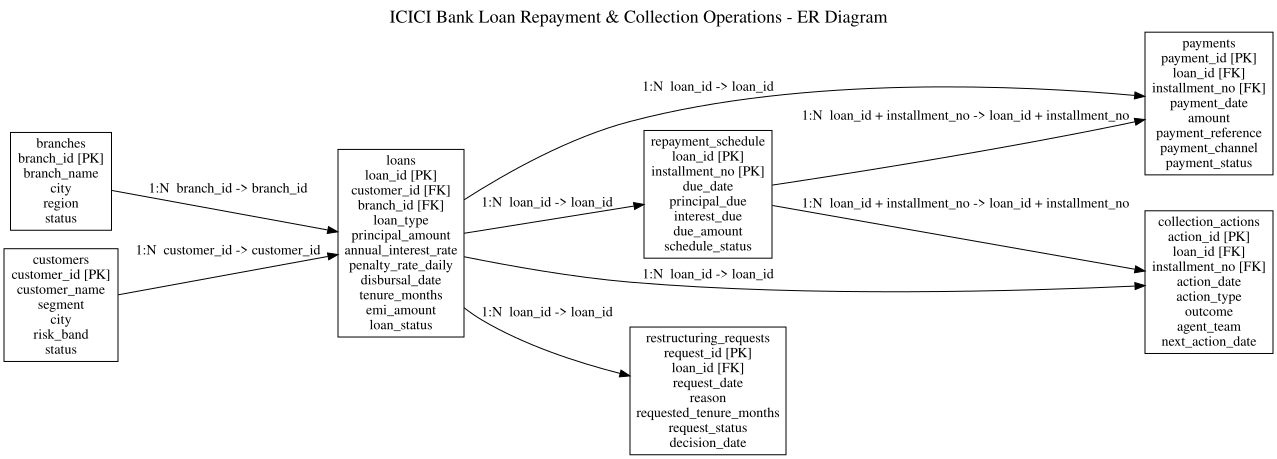

In [ ]:
# SQL DEVELOPER WORKSPACE
# TODO: Define all seven required core tables and all eight required relationships.
# SQL DEVELOPER WORKSPACE
developer_tables = {
    "branches": ["branch_id PK", "branch_name", "city", "region", "status"],
    "customers": ["customer_id PK", "customer_name", "segment", "city", "risk_band", "status"],
    "loans": ["loan_id PK", "customer_id FK", "branch_id FK", "loan_type", "principal_amount",
              "annual_interest_rate", "penalty_rate_daily", "disbursal_date", "tenure_months",
              "emi_amount", "loan_status"],
    "repayment_schedule": ["loan_id PK FK", "installment_no PK", "due_date", "principal_due",
                           "interest_due", "due_amount", "schedule_status"],
    "payments": ["payment_id PK", "loan_id FK", "installment_no FK", "payment_date", "amount",
                 "payment_reference", "payment_channel", "payment_status"],
    "collection_actions": ["action_id PK", "loan_id FK", "installment_no FK", "action_date",
                           "action_type", "outcome", "agent_team", "next_action_date"],
    "restructuring_requests": ["request_id PK", "loan_id FK", "request_date", "reason",
                               "requested_tenure_months", "request_status", "decision_date"],
}

developer_relationships = [
    ("customers", "customer_id", "loans", "customer_id", "1:N"),
    ("branches", "branch_id", "loans", "branch_id", "1:N"),
    ("loans", "loan_id", "repayment_schedule", "loan_id", "1:N"),
    ("loans", "loan_id", "payments", "loan_id", "1:N"),
    ("repayment_schedule", "loan_id + installment_no", "payments", "loan_id + installment_no", "1:N"),
    ("loans", "loan_id", "collection_actions", "loan_id", "1:N"),
    ("repayment_schedule", "loan_id + installment_no", "collection_actions", "loan_id + installment_no", "1:N"),
    ("loans", "loan_id", "restructuring_requests", "loan_id", "1:N"),
]

validate_er_design(developer_tables, developer_relationships)


### Expected Output - ER-1

- Exactly seven connected core tables.
- Primary and foreign-key markers are present.
- `repayment_schedule` uses the composite primary key `(loan_id, installment_no)`.
- `payments` and `collection_actions` reference that composite schedule key.
- All eight required relationships validate.
- A readable ER diagram is rendered when the activity passes.

# 3. API Operations

Complete five independent API-consumption activities. The temporary service is provided by setup, and every mutable practice record is reset before use.

In [ ]:
display(api_documentation)


,Method,Endpoint,Purpose,Expected status
0,GET,/branches,Read branch master records,200
1,GET,/customers,Read customer records,200
2,GET,/loans,Read loan accounts,200
3,GET,/repayment_schedules,Read repayment schedule rows,200
4,GET,/payments,Read payments with filters and pagination,200
5,GET,/payments/{id},Read one payment,200 / 404
6,POST,/collection_actions,Create one collection action,201 / 400 / 409
7,PUT,/payments/{id},Replace a complete payment record,200 / 400 / 404
8,PATCH,/collection_actions/{id},Update selected collection-action fields,200 / 404
9,DELETE,/payments/{id},Delete one payment record,200 / 404


## API-Q1 - Filtered GET

**Business requirement:** Fetch exactly five successful UPI payment records using `limit`, `payment_channel`, and `payment_status` filters.

**How to approach:** Use the provided endpoint/payload and write only the required `requests` call(s) in the SQL Developer workspace. Use a timeout. Mutable practice records are reset before the workspace runs.

In [ ]:
# SQL DEVELOPER WORKSPACE
# SQL DEVELOPER WORKSPACE
q1_sql = """
SELECT
    p.payment_id,
    c.customer_name,
    b.branch_name,
    l.loan_type,
    p.payment_channel,
    p.amount AS payment_amount,
    p.payment_date
FROM payments p
JOIN loans l ON p.loan_id = l.loan_id
JOIN customers c ON l.customer_id = c.customer_id
JOIN branches b ON l.branch_id = b.branch_id
WHERE p.payment_status = 'SUCCESS'
ORDER BY p.amount DESC
LIMIT 10;
"""

validate_sql('Q1', q1_sql)

Q1: Passed - columns=True; rows=10/10; key_result=True


,payment_id,customer_name,branch_name,loan_type,payment_channel,payment_amount,payment_date
0,PAY0002664,Aditi Rao 171,Pune Retail Lending 2,HOME_LOAN,UPI,"698,628.75",2026-01-16
1,PAY0001613,Neel Mehta 188,Chennai Retail Lending 3,HOME_LOAN,UPI,"698,128.75",2026-02-07
2,PAY0001614,Neel Mehta 188,Chennai Retail Lending 3,HOME_LOAN,CASH,"698,128.75",2026-03-05
3,PAY0001615,Neel Mehta 188,Chennai Retail Lending 3,HOME_LOAN,CHEQUE,"698,128.75",2026-04-09
4,PAY0001616,Neel Mehta 188,Chennai Retail Lending 3,HOME_LOAN,NEFT,"698,128.75",2026-05-15
5,PAY0001617,Neel Mehta 188,Chennai Retail Lending 3,HOME_LOAN,NACH,"698,128.75",2026-06-05
6,PAY0001618,Neel Mehta 188,Chennai Retail Lending 3,HOME_LOAN,NACH,"698,128.75",2026-07-08
7,PAY0002473,Dev Kapoor 222,Delhi Retail Lending 2,HOME_LOAN,CHEQUE,"698,128.75",2026-02-21
8,PAY0002474,Dev Kapoor 222,Delhi Retail Lending 2,HOME_LOAN,UPI,"698,128.75",2026-03-26
9,PAY0002476,Dev Kapoor 222,Delhi Retail Lending 2,HOME_LOAN,UPI,"698,128.75",2026-04-22


,payment_id,customer_name,branch_name,loan_type,payment_channel,payment_amount,payment_date
0,PAY0002664,Aditi Rao 171,Pune Retail Lending 2,HOME_LOAN,UPI,"698,628.75",2026-01-16
1,PAY0001613,Neel Mehta 188,Chennai Retail Lending 3,HOME_LOAN,UPI,"698,128.75",2026-02-07
2,PAY0001614,Neel Mehta 188,Chennai Retail Lending 3,HOME_LOAN,CASH,"698,128.75",2026-03-05
3,PAY0001615,Neel Mehta 188,Chennai Retail Lending 3,HOME_LOAN,CHEQUE,"698,128.75",2026-04-09
4,PAY0001616,Neel Mehta 188,Chennai Retail Lending 3,HOME_LOAN,NEFT,"698,128.75",2026-05-15
5,PAY0001617,Neel Mehta 188,Chennai Retail Lending 3,HOME_LOAN,NACH,"698,128.75",2026-06-05
6,PAY0001618,Neel Mehta 188,Chennai Retail Lending 3,HOME_LOAN,NACH,"698,128.75",2026-07-08
7,PAY0002473,Dev Kapoor 222,Delhi Retail Lending 2,HOME_LOAN,CHEQUE,"698,128.75",2026-02-21
8,PAY0002474,Dev Kapoor 222,Delhi Retail Lending 2,HOME_LOAN,UPI,"698,128.75",2026-03-26
9,PAY0002476,Dev Kapoor 222,Delhi Retail Lending 2,HOME_LOAN,UPI,"698,128.75",2026-04-22


In [ ]:
# SQL DEVELOPER WORKSPACE
# TODO: Write the filtered GET request using params for limit=5, payment_channel='UPI', and payment_status='SUCCESS'.
api_q1_response = requests.get(
    f'{API_BASE_URL}/payments',
    params={'limit': 5, 'payment_channel': 'UPI', 'payment_status': 'SUCCESS'},
    timeout=10
)
validate_api_q1(api_q1_response)


,payment_id,loan_id,installment_no,payment_date,amount,payment_reference,payment_channel,payment_status
0,PAY0000003,L000001,3,2026-03-16,"34,047.06",PAYREF0000003,UPI,SUCCESS
1,PAY0000006,L000001,5,2026-05-08,"40,055.37",PAYREF0000006,UPI,SUCCESS
2,PAY0000008,L000001,6,2026-06-08,"40,055.37",PAYREF0000008,UPI,SUCCESS
3,PAY0000009,L000001,7,2026-07-09,"40,055.37",PAYREF0000009,UPI,SUCCESS
4,PAY0000013,L000002,4,2026-04-15,"30,351.85",PAYREF0000013,UPI,SUCCESS


API-Q1: Passed - HTTP 200, five records, and every record is SUCCESS via UPI.


### Expected Output - API-Q1

| Check | Expected |
|---|---|
| HTTP status | 200 |
| Records | 5 |
| payment_status | SUCCESS for every row |
| payment_channel | UPI for every row |

**Hint:** `requests.get(..., params=..., timeout=10)`.

## API-Q2 - POST collection action

**Business requirement:** Create the provided collection-action update for a repayment follow-up.

**How to approach:** Use the provided endpoint/payload and write only the required `requests` call(s) in the SQL Developer workspace. Use a timeout. Mutable practice records are reset before the workspace runs.

In [ ]:
api_store['collection_actions']=[r for r in api_store['collection_actions'] if r['action_id']!='ACT-DEVELOPER-POST']
post_payload={'action_id':'ACT-DEVELOPER-POST','loan_id':'L000001','installment_no':7,'action_date':'2026-08-01','action_type':'CALL','outcome':'PROMISE_TO_PAY','agent_team':'COLLECTION_NORTH','next_action_date':'2026-08-04'}
# SQL DEVELOPER WORKSPACE
# TODO: POST post_payload to the collection_actions endpoint.
api_q2_response = requests.post(
    f'{API_BASE_URL}/collection_actions',
    json=post_payload,
    timeout=10
)
validate_api_q2(api_q2_response,'ACT-DEVELOPER-POST')


API-Q2: Passed - Collection action created with the required payload.


,action_id,loan_id,installment_no,action_date,action_type,outcome,agent_team,next_action_date
0,ACT-DEVELOPER-POST,L000001,7,2026-08-01,CALL,PROMISE_TO_PAY,COLLECTION_NORTH,2026-08-04


### Expected Output - API-Q2

| Check | Expected |
|---|---|
| HTTP status | 201 |
| action_id | ACT-DEVELOPER-POST |
| loan_id | L000001 |
| installment_no | 7 |

**Hint:** `requests.post(..., json=post_payload, timeout=10)`.

## API-Q3 - Complete PUT replacement

**Business requirement:** Replace the complete reset practice payment with `put_payload`.

**How to approach:** Use the provided endpoint/payload and write only the required `requests` call(s) in the SQL Developer workspace. Use a timeout. Mutable practice records are reset before the workspace runs.

In [ ]:
reset_api_practice_record('PAY_API_PUT_001')
put_payload={'payment_id':'PAY_API_PUT_001','loan_id':'L000001','installment_no':1,'payment_date':'2026-07-14','amount':24500.0,'payment_reference':'REF-PUT-REPLACED','payment_channel':'NEFT','payment_status':'SUCCESS'}
# SQL DEVELOPER WORKSPACE
# TODO: PUT put_payload to replace the complete practice payment.
api_q3_response = requests.put(
    f'{API_BASE_URL}/payments/PAY_API_PUT_001',
    json=put_payload,
    timeout=10
)
validate_api_q3(api_q3_response,put_payload)


API-Q3: Passed - Complete payment replacement validated.


,payment_id,loan_id,installment_no,payment_date,amount,payment_reference,payment_channel,payment_status
0,PAY_API_PUT_001,L000001,1,2026-07-14,"24,500.00",REF-PUT-REPLACED,NEFT,SUCCESS


### Expected Output - API-Q3

| Check | Expected |
|---|---|
| HTTP status | 200 |
| Complete replacement | Every response field equals `put_payload` |
| Unexpected retained fields | None |

**Hint:** `requests.put(..., json=put_payload, timeout=10)`.

## API-Q4 - Partial PATCH update

**Business requirement:** Update only the outcome and next-action date of the reset collection action.

**How to approach:** Use the provided endpoint/payload and write only the required `requests` call(s) in the SQL Developer workspace. Use a timeout. Mutable practice records are reset before the workspace runs.

In [ ]:
reset_api_practice_record('COL_API_PATCH_001')
before_patch=requests.get(f'{API_BASE_URL}/collection_actions/COL_API_PATCH_001',timeout=10).json(); patch_payload={'outcome':'PROMISE_TO_PAY','next_action_date':'2026-08-05'}
# SQL DEVELOPER WORKSPACE
# TODO: PATCH only the fields in patch_payload.
api_q4_response = requests.patch(
    f'{API_BASE_URL}/collection_actions/COL_API_PATCH_001',
    json=patch_payload,
    timeout=10
)
validate_api_q4(api_q4_response,before_patch,patch_payload)


API-Q4: Passed - Targeted collection-action fields changed and untargeted fields were preserved.


,action_id,loan_id,installment_no,action_date,action_type,outcome,agent_team,next_action_date
0,COL_API_PATCH_001,L000003,7,2026-07-30,CALL,PROMISE_TO_PAY,DIGITAL_COLLECTIONS,2026-08-05


### Expected Output - API-Q4

| Check | Expected |
|---|---|
| HTTP status | 200 |
| outcome | PROMISE_TO_PAY |
| next_action_date | 2026-08-05 |
| Untargeted fields | Unchanged |

**Hint:** `requests.patch(..., json=patch_payload, timeout=10)`.

## API-Q5 - GET -> DELETE -> GET verification

**Business requirement:** Read the reset practice payment, delete it, and fetch it again.

**How to approach:** Use the provided endpoint/payload and write only the required `requests` call(s) in the SQL Developer workspace. Use a timeout. Mutable practice records are reset before the workspace runs.

In [ ]:
reset_api_practice_record('PAY_API_DELETE_001')
# SQL DEVELOPER WORKSPACE
# TODO: GET the practice payment, DELETE it, then GET it again.
api_q5_before = requests.get(f'{API_BASE_URL}/payments/PAY_API_DELETE_001', timeout=10)
api_q5_delete = requests.delete(f'{API_BASE_URL}/payments/PAY_API_DELETE_001', timeout=10)
api_q5_after = requests.get(f'{API_BASE_URL}/payments/PAY_API_DELETE_001', timeout=10)
validate_api_q5(api_q5_before,api_q5_delete,api_q5_after)


API-Q5: Passed - status sequence=[200, 200, 404]; expected=[200, 200, 404]


### Expected Output - API-Q5

| Request | Expected status |
|---|---:|
| GET before delete | 200 |
| DELETE | 200 |
| GET after delete | 404 |

**Hint:** Use `requests.get`, `requests.delete`, then `requests.get` with timeouts.

# 4. SQL Developer Questions

Use SQL for the business analysis. Python/Pandas helpers only execute, display, and validate the SQL result.

In [ ]:
display(pd.DataFrame([{'table':t,'rows':conn.execute('SELECT COUNT(*) FROM '+t).fetchone()[0]} for t in ['branches','customers','loans','repayment_schedule','payments','collection_actions','restructuring_requests','loan_exceptions']]))


,table,rows
0,branches,24
1,customers,320
2,loans,420
3,repayment_schedule,2940
4,payments,3089
5,collection_actions,291
6,restructuring_requests,72
7,loan_exceptions,1105


## 4.1 Foundations, Aggregation, and Joins

## Q1 - Show the ten largest successful repayment receipts so the control desk can review high-value credits

**Stakeholder:** Collections Operations Lead

**Business requirement:** Show the ten largest successful repayment receipts so the control desk can review high-value credits.

**Tables to use:** `payments`, `loans`, `customers`, `branches`

**How to approach:** Join successful payments to loans, customers, and branches; sort by payment amount descending and use `LIMIT 10`.


In [ ]:
# SQL DEVELOPER WORKSPACE
# TODO: Write the SQL query for Q1.
# SQL DEVELOPER WORKSPACE
# TODO: Write the SQL query for Q1.
q1_sql = '''
SELECT p.payment_id, c.customer_name, b.branch_name, l.loan_type,
       p.payment_channel, p.amount AS payment_amount, p.payment_date
FROM payments p
JOIN loans l ON p.loan_id = l.loan_id
JOIN customers c ON l.customer_id = c.customer_id
JOIN branches b ON l.branch_id = b.branch_id
WHERE p.payment_status = 'SUCCESS'
ORDER BY p.amount DESC
LIMIT 10;
'''
validate_sql('Q1', q1_sql)


Q1: Passed - columns=True; rows=10/10; key_result=True


,payment_id,customer_name,branch_name,loan_type,payment_channel,payment_amount,payment_date
0,PAY0002664,Aditi Rao 171,Pune Retail Lending 2,HOME_LOAN,UPI,"698,628.75",2026-01-16
1,PAY0001613,Neel Mehta 188,Chennai Retail Lending 3,HOME_LOAN,UPI,"698,128.75",2026-02-07
2,PAY0001614,Neel Mehta 188,Chennai Retail Lending 3,HOME_LOAN,CASH,"698,128.75",2026-03-05
3,PAY0001615,Neel Mehta 188,Chennai Retail Lending 3,HOME_LOAN,CHEQUE,"698,128.75",2026-04-09
4,PAY0001616,Neel Mehta 188,Chennai Retail Lending 3,HOME_LOAN,NEFT,"698,128.75",2026-05-15
5,PAY0001617,Neel Mehta 188,Chennai Retail Lending 3,HOME_LOAN,NACH,"698,128.75",2026-06-05
6,PAY0001618,Neel Mehta 188,Chennai Retail Lending 3,HOME_LOAN,NACH,"698,128.75",2026-07-08
7,PAY0002473,Dev Kapoor 222,Delhi Retail Lending 2,HOME_LOAN,CHEQUE,"698,128.75",2026-02-21
8,PAY0002474,Dev Kapoor 222,Delhi Retail Lending 2,HOME_LOAN,UPI,"698,128.75",2026-03-26
9,PAY0002476,Dev Kapoor 222,Delhi Retail Lending 2,HOME_LOAN,UPI,"698,128.75",2026-04-22


,payment_id,customer_name,branch_name,loan_type,payment_channel,payment_amount,payment_date
0,PAY0002664,Aditi Rao 171,Pune Retail Lending 2,HOME_LOAN,UPI,"698,628.75",2026-01-16
1,PAY0001613,Neel Mehta 188,Chennai Retail Lending 3,HOME_LOAN,UPI,"698,128.75",2026-02-07
2,PAY0001614,Neel Mehta 188,Chennai Retail Lending 3,HOME_LOAN,CASH,"698,128.75",2026-03-05
3,PAY0001615,Neel Mehta 188,Chennai Retail Lending 3,HOME_LOAN,CHEQUE,"698,128.75",2026-04-09
4,PAY0001616,Neel Mehta 188,Chennai Retail Lending 3,HOME_LOAN,NEFT,"698,128.75",2026-05-15
5,PAY0001617,Neel Mehta 188,Chennai Retail Lending 3,HOME_LOAN,NACH,"698,128.75",2026-06-05
6,PAY0001618,Neel Mehta 188,Chennai Retail Lending 3,HOME_LOAN,NACH,"698,128.75",2026-07-08
7,PAY0002473,Dev Kapoor 222,Delhi Retail Lending 2,HOME_LOAN,CHEQUE,"698,128.75",2026-02-21
8,PAY0002474,Dev Kapoor 222,Delhi Retail Lending 2,HOME_LOAN,UPI,"698,128.75",2026-03-26
9,PAY0002476,Dev Kapoor 222,Delhi Retail Lending 2,HOME_LOAN,UPI,"698,128.75",2026-04-22


#### Expected Output - Q1

| Column | Requirement |
|---|---|
| `payment_id` | Required output column |
| `customer_name` | Required output column |
| `branch_name` | Required output column |
| `loan_type` | Required output column |
| `payment_channel` | Required output column |
| `payment_amount` | Required output column |
| `payment_date` | Required output column |

- **Expected row count:** `10`
- **Stable first-row check:** `payment_id = PAY0002664`, `customer_name = Aditi Rao 171`, `branch_name = Pune Retail Lending 2`
- **Hint:** JOIN, WHERE, ORDER BY, LIMIT
- Validation checks exact column order, row count, stable first-row values, and overall status.

## Q2 - Identify branches with a meaningful volume of successful repayments and summarize value collected

**Stakeholder:** Regional Collections Manager

**Business requirement:** Identify branches with at least **70 successful payments** and more than **INR 1,500,000 total collected** as of the review date.

**Tables to use:** `branches`, `loans`, `payments`

**How to approach:** Aggregate successful payment count and value by branch; use `HAVING COUNT(*) >= 70 AND SUM(amount) > 1500000`. Order by total collected amount descending, then branch ID.


In [ ]:
# SQL DEVELOPER WORKSPACE
# TODO: Write the SQL query for Q2.
q2_sql = '''
SELECT b.branch_id, b.branch_name,
       COUNT(*) AS successful_payment_count,
       SUM(p.amount) AS total_collected_amount
FROM payments p
JOIN loans l ON p.loan_id = l.loan_id
JOIN branches b ON l.branch_id = b.branch_id
WHERE p.payment_status = 'SUCCESS'
GROUP BY b.branch_id, b.branch_name
HAVING COUNT(*) >= 70 AND SUM(p.amount) > 1500000
ORDER BY total_collected_amount DESC, b.branch_id;
'''
validate_sql('Q2',q2_sql)


Q2: Passed - columns=True; rows=22/22; key_result=True


,branch_id,branch_name,successful_payment_count,total_collected_amount
0,BR022,Bhubaneswar Retail Lending 1,163,"15,343,994.38"
1,BR007,Delhi Retail Lending 1,121,"14,007,958.33"
2,BR006,Pune Retail Lending 3,117,"13,132,757.81"
3,BR008,Delhi Retail Lending 2,141,"13,101,707.31"
4,BR015,Bengaluru Retail Lending 3,157,"13,055,108.69"
5,BR016,Chennai Retail Lending 1,132,"12,096,229.94"
6,BR005,Pune Retail Lending 2,99,"11,874,470.80"
7,BR013,Bengaluru Retail Lending 1,126,"11,326,407.23"
8,BR010,Jaipur Retail Lending 1,106,"10,834,979.01"
9,BR024,Bhubaneswar Retail Lending 3,140,"10,742,388.26"


,branch_id,branch_name,successful_payment_count,total_collected_amount
0,BR022,Bhubaneswar Retail Lending 1,163,"15,343,994.38"
1,BR007,Delhi Retail Lending 1,121,"14,007,958.33"
2,BR006,Pune Retail Lending 3,117,"13,132,757.81"
3,BR008,Delhi Retail Lending 2,141,"13,101,707.31"
4,BR015,Bengaluru Retail Lending 3,157,"13,055,108.69"
5,BR016,Chennai Retail Lending 1,132,"12,096,229.94"
6,BR005,Pune Retail Lending 2,99,"11,874,470.80"
7,BR013,Bengaluru Retail Lending 1,126,"11,326,407.23"
8,BR010,Jaipur Retail Lending 1,106,"10,834,979.01"
9,BR024,Bhubaneswar Retail Lending 3,140,"10,742,388.26"


#### Expected Output - Q2

| Column | Requirement |
|---|---|
| `branch_id` | Required output column |
| `branch_name` | Required output column |
| `successful_payment_count` | Required output column |
| `total_collected_amount` | Required output column |

- **Expected row count:** `22`
- **Stable first-row check:** `branch_id = BR022`, `branch_name = Bhubaneswar Retail Lending 1`, `successful_payment_count = 163`
- **Hint:** GROUP BY, SUM, COUNT, HAVING
- Validation checks exact column order, row count, stable first-row values, and overall status.

## Q3 - Classify every scheduled instalment as paid, missing, underpaid, or overpaid as of the review date

**Stakeholder:** Loan Operations Manager

**Business requirement:** Classify every scheduled instalment as paid, missing, underpaid, or overpaid as of the review date.

**Tables to use:** `repayment_schedule`, `payments`

**How to approach:** Aggregate successful payments per instalment, LEFT JOIN to the schedule, then use COALESCE and CASE.

In [ ]:
# SQL DEVELOPER WORKSPACE
# TODO: Write the SQL query for Q3.
q3_sql = '''
WITH paid AS (
  SELECT loan_id, installment_no, SUM(amount) AS paid_amount
  FROM payments
  WHERE payment_status = 'SUCCESS'
  GROUP BY loan_id, installment_no
)
SELECT rs.loan_id, rs.installment_no, rs.due_date, rs.due_amount,
       COALESCE(paid.paid_amount, 0) AS paid_amount,
       rs.due_amount - COALESCE(paid.paid_amount, 0) AS balance_amount,
       CASE
         WHEN COALESCE(paid.paid_amount, 0) = 0 THEN 'MISSING'
         WHEN COALESCE(paid.paid_amount, 0) < rs.due_amount THEN 'UNDERPAID'
         WHEN COALESCE(paid.paid_amount, 0) > rs.due_amount THEN 'OVERPAID'
         ELSE 'PAID'
       END AS reconciliation_status
FROM repayment_schedule rs
LEFT JOIN paid ON rs.loan_id = paid.loan_id AND rs.installment_no = paid.installment_no
ORDER BY rs.loan_id, rs.installment_no;
'''
validate_sql('Q3',q3_sql)


Q3: Passed - columns=True; rows=2940/2940; key_result=True


,loan_id,installment_no,due_date,due_amount,paid_amount,balance_amount,reconciliation_status
0,L000001,1,2026-01-06,"40,055.37","40,055.37",0.00,PAID
1,L000001,2,2026-02-06,"40,055.37",0.00,"40,055.37",MISSING
2,L000001,3,2026-03-06,"40,055.37","34,047.06","6,008.31",UNDERPAID
3,L000001,4,2026-04-06,"40,055.37","40,055.37",0.00,PAID
4,L000001,5,2026-05-06,"40,055.37","40,055.37",0.00,PAID
...,...,...,...,...,...,...,...
2935,L000420,3,2026-03-05,"8,011.07","8,011.07",0.00,PAID
2936,L000420,4,2026-04-05,"8,011.07","8,011.07",0.00,PAID
2937,L000420,5,2026-05-05,"8,011.07","8,011.07",0.00,PAID
2938,L000420,6,2026-06-05,"8,011.07","8,011.07",0.00,PAID


,loan_id,installment_no,due_date,due_amount,paid_amount,balance_amount,reconciliation_status
0,L000001,1,2026-01-06,"40,055.37","40,055.37",0.00,PAID
1,L000001,2,2026-02-06,"40,055.37",0.00,"40,055.37",MISSING
2,L000001,3,2026-03-06,"40,055.37","34,047.06","6,008.31",UNDERPAID
3,L000001,4,2026-04-06,"40,055.37","40,055.37",0.00,PAID
4,L000001,5,2026-05-06,"40,055.37","40,055.37",0.00,PAID
...,...,...,...,...,...,...,...
2935,L000420,3,2026-03-05,"8,011.07","8,011.07",0.00,PAID
2936,L000420,4,2026-04-05,"8,011.07","8,011.07",0.00,PAID
2937,L000420,5,2026-05-05,"8,011.07","8,011.07",0.00,PAID
2938,L000420,6,2026-06-05,"8,011.07","8,011.07",0.00,PAID


#### Expected Output - Q3

| Column | Requirement |
|---|---|
| `loan_id` | Required output column |
| `installment_no` | Required output column |
| `due_date` | Required output column |
| `due_amount` | Required output column |
| `paid_amount` | Required output column |
| `balance_amount` | Required output column |
| `reconciliation_status` | Required output column |

- **Expected row count:** `2940`
- **Stable first-row check:** `loan_id = L000001`, `installment_no = 1`, `due_date = 2026-01-06`
- **Hint:** CTE, LEFT JOIN, COALESCE, CASE
- Validation checks exact column order, row count, stable first-row values, and overall status.

## Q4 - List due instalments that still have no successful payment as of the review date

**Stakeholder:** Collections Operations Lead

**Business requirement:** List due instalments that still have no successful payment as of the review date.

**Tables to use:** `repayment_schedule`, `payments`, `loans`, `branches`

**How to approach:** LEFT JOIN an aggregate of successful payments to the schedule, retain due rows where no successful receipt exists, then join through loans to branches for the branch name.


In [ ]:
# SQL DEVELOPER WORKSPACE
# TODO: Write the SQL query for Q4.
q4_sql = '''
WITH paid AS (
  SELECT loan_id, installment_no
  FROM payments WHERE payment_status = 'SUCCESS'
  GROUP BY loan_id, installment_no
)
SELECT rs.loan_id, rs.installment_no, rs.due_date, rs.due_amount, b.branch_name
FROM repayment_schedule rs
JOIN loans l ON rs.loan_id = l.loan_id
JOIN branches b ON l.branch_id = b.branch_id
LEFT JOIN paid ON rs.loan_id = paid.loan_id AND rs.installment_no = paid.installment_no
WHERE rs.due_date < '2026-08-01' AND paid.loan_id IS NULL
ORDER BY rs.due_date, rs.loan_id, rs.installment_no;
'''
validate_sql('Q4', q4_sql)


Q4: Passed - columns=True; rows=194/194; key_result=True


,loan_id,installment_no,due_date,due_amount,branch_name
0,L000060,1,2026-01-05,"2,670.36",Bengaluru Retail Lending 3
1,L000021,1,2026-01-06,"62,509.80",Pune Retail Lending 2
2,L000322,1,2026-01-07,"46,793.77",Pune Retail Lending 3
3,L000362,1,2026-01-07,"47,874.32",Pune Retail Lending 1
4,L000003,1,2026-01-08,"31,210.38",Chennai Retail Lending 3
...,...,...,...,...,...
189,L000054,7,2026-07-19,"350,269.81",Jaipur Retail Lending 2
190,L000374,7,2026-07-19,"17,499.57",Delhi Retail Lending 1
191,L000017,7,2026-07-22,"218,165.24",Delhi Retail Lending 2
192,L000357,7,2026-07-22,"87,497.86",Pune Retail Lending 1


,loan_id,installment_no,due_date,due_amount,branch_name
0,L000060,1,2026-01-05,"2,670.36",Bengaluru Retail Lending 3
1,L000021,1,2026-01-06,"62,509.80",Pune Retail Lending 2
2,L000322,1,2026-01-07,"46,793.77",Pune Retail Lending 3
3,L000362,1,2026-01-07,"47,874.32",Pune Retail Lending 1
4,L000003,1,2026-01-08,"31,210.38",Chennai Retail Lending 3
...,...,...,...,...,...
189,L000054,7,2026-07-19,"350,269.81",Jaipur Retail Lending 2
190,L000374,7,2026-07-19,"17,499.57",Delhi Retail Lending 1
191,L000017,7,2026-07-22,"218,165.24",Delhi Retail Lending 2
192,L000357,7,2026-07-22,"87,497.86",Pune Retail Lending 1


#### Expected Output - Q4

| Column | Requirement |
|---|---|
| `loan_id` | Required output column |
| `installment_no` | Required output column |
| `due_date` | Required output column |
| `due_amount` | Required output column |
| `branch_name` | Required output column |

- **Expected row count:** `194`
- **Stable first-row check:** `loan_id = L000060`, `installment_no = 1`, `due_date = 2026-01-05`
- **Hint:** LEFT JOIN, anti-join, NULL
- Validation checks exact column order, row count, stable first-row values, and overall status.

## 4.2 Set Operations, Functions, Subqueries, and CTEs

## Q5 - Find loans that are both overdue and have an open collection follow-up exception

**Stakeholder:** Portfolio Risk Lead

**Business requirement:** Find loans that are both overdue and have an open collection follow-up exception.

**Tables to use:** `repayment_schedule`, `payments`, `loan_exceptions`, `loans`, `customers`, `branches`

**How to approach:** Build the overdue-loan set and intersect it with loans carrying open follow-up exceptions; join the resulting loan IDs to customer and branch master data for the required names.


In [ ]:
# SQL DEVELOPER WORKSPACE
# TODO: Write the SQL query for Q5.
q5_sql = '''
WITH overdue_loans AS (
  SELECT DISTINCT rs.loan_id
  FROM repayment_schedule rs
  LEFT JOIN (
    SELECT loan_id, installment_no, SUM(amount) AS paid_amount
    FROM payments WHERE payment_status = 'SUCCESS'
    GROUP BY loan_id, installment_no
  ) p ON rs.loan_id = p.loan_id AND rs.installment_no = p.installment_no
  WHERE rs.due_date < '2026-08-01' AND COALESCE(p.paid_amount, 0) < rs.due_amount
),
exception_loans AS (
  SELECT DISTINCT loan_id
  FROM loan_exceptions
  WHERE exception_type = 'COLLECTION_FOLLOWUP_OVERDUE' AND resolution_status = 'OPEN'
),
matched_loans AS (
  SELECT loan_id FROM overdue_loans
  INTERSECT
  SELECT loan_id FROM exception_loans
)
SELECT m.loan_id, c.customer_name, b.branch_name
FROM matched_loans m
JOIN loans l ON m.loan_id = l.loan_id
JOIN customers c ON l.customer_id = c.customer_id
JOIN branches b ON l.branch_id = b.branch_id
ORDER BY m.loan_id;
'''
validate_sql('Q5',q5_sql)


Q5: Passed - columns=True; rows=162/162; key_result=True


,loan_id,customer_name,branch_name
0,L000005,Ishaan Gupta 288,Chennai Retail Lending 2
1,L000006,Kavya Agarwal 254,Bhubaneswar Retail Lending 2
2,L000007,Arjun Rao 251,Bhubaneswar Retail Lending 3
3,L000009,Neel Desai 127,Mumbai Retail Lending 3
4,L000012,Saanvi Iyer 274,Bengaluru Retail Lending 3
...,...,...,...
157,L000407,Diya Rao 007,Mumbai Retail Lending 2
158,L000414,Arjun Singh 259,Delhi Retail Lending 1
159,L000417,Saanvi Kapoor 195,Kolkata Retail Lending 1
160,L000418,Manav Shah 237,Delhi Retail Lending 1


,loan_id,customer_name,branch_name
0,L000005,Ishaan Gupta 288,Chennai Retail Lending 2
1,L000006,Kavya Agarwal 254,Bhubaneswar Retail Lending 2
2,L000007,Arjun Rao 251,Bhubaneswar Retail Lending 3
3,L000009,Neel Desai 127,Mumbai Retail Lending 3
4,L000012,Saanvi Iyer 274,Bengaluru Retail Lending 3
...,...,...,...
157,L000407,Diya Rao 007,Mumbai Retail Lending 2
158,L000414,Arjun Singh 259,Delhi Retail Lending 1
159,L000417,Saanvi Kapoor 195,Kolkata Retail Lending 1
160,L000418,Manav Shah 237,Delhi Retail Lending 1


#### Expected Output - Q5

| Column | Requirement |
|---|---|
| `loan_id` | Required output column |
| `customer_name` | Required output column |
| `branch_name` | Required output column |

- **Expected row count:** `162`
- **Stable first-row check:** `loan_id = L000005`, `customer_name = Ishaan Gupta 288`, `branch_name = Chennai Retail Lending 2`
- **Hint:** INTERSECT, CTE
- Validation checks exact column order, row count, stable first-row values, and overall status.

## Q6 - Produce a business-readable borrower/loan risk report with days past due and delinquency stage

**Stakeholder:** Portfolio Risk Lead

**Business requirement:** Produce the **40 highest-risk loans** with days past due, overdue amount, open exception count, and delinquency stage as of the review date.

**Tables to use:** `loans`, `customers`, `repayment_schedule`, `payments`, `loan_exceptions`

**How to approach:** Aggregate successful payments by instalment, calculate DPD from due date, count open exceptions by loan, and use `UPPER`, `SUBSTR`, `CAST`, `COALESCE`, and `CASE`. Order by maximum DPD descending, overdue amount descending, then loan ID; return `LIMIT 40`.


In [ ]:
# SQL DEVELOPER WORKSPACE
# TODO: Write the SQL query for Q6.
q6_sql = '''
WITH overdue_inst AS (
  SELECT rs.loan_id, rs.due_amount,
         COALESCE(p.paid_amount, 0) AS paid_amount,
         CAST(julianday('2026-08-01') - julianday(rs.due_date) AS INTEGER) AS days_overdue
  FROM repayment_schedule rs
  LEFT JOIN (
    SELECT loan_id, installment_no, SUM(amount) AS paid_amount
    FROM payments WHERE payment_status = 'SUCCESS'
    GROUP BY loan_id, installment_no
  ) p ON rs.loan_id = p.loan_id AND rs.installment_no = p.installment_no
  WHERE rs.due_date < '2026-08-01' AND COALESCE(p.paid_amount, 0) < rs.due_amount
),
loan_overdue AS (
  SELECT loan_id, MAX(days_overdue) AS max_days_overdue,
         SUM(due_amount - paid_amount) AS overdue_amount
  FROM overdue_inst GROUP BY loan_id
),
exception_counts AS (
  SELECT loan_id, COUNT(*) AS open_exceptions
  FROM loan_exceptions WHERE resolution_status = 'OPEN'
  GROUP BY loan_id
)
SELECT l.loan_id,
       UPPER(c.customer_name) AS customer_name_upper,
       SUBSTR(l.loan_type, 1, 12) AS loan_type_short,
       CAST(julianday('2026-08-01') - julianday(l.disbursal_date) AS INTEGER) AS days_on_book,
       lo.max_days_overdue, lo.overdue_amount,
       COALESCE(ec.open_exceptions, 0) AS open_exceptions,
       CASE
         WHEN lo.max_days_overdue > 90 THEN 'DPD_90_PLUS'
         WHEN lo.max_days_overdue > 60 THEN 'DPD_61_90'
         WHEN lo.max_days_overdue > 30 THEN 'DPD_31_60'
         WHEN lo.max_days_overdue > 0 THEN 'DPD_1_30'
         ELSE 'CURRENT'
       END AS delinquency_stage
FROM loan_overdue lo
JOIN loans l ON lo.loan_id = l.loan_id
JOIN customers c ON l.customer_id = c.customer_id
LEFT JOIN exception_counts ec ON ec.loan_id = l.loan_id
ORDER BY lo.max_days_overdue DESC, lo.overdue_amount DESC, l.loan_id
LIMIT 40;
'''
validate_sql('Q6',q6_sql)


Q6: Passed - columns=True; rows=40/40; key_result=True


,loan_id,customer_name_upper,loan_type_short,days_on_book,max_days_overdue,overdue_amount,open_exceptions,delinquency_stage
0,L000420,ADITI VERMA 304,PERSONAL_LOA,273,208,"9,212.73",5,DPD_90_PLUS
1,L000060,DIYA RAO 013,PERSONAL_LOA,378,208,"2,670.36",2,DPD_90_PLUS
2,L000361,SAANVI SHARMA 262,HOME_LOAN,340,207,"349,060.02",5,DPD_90_PLUS
3,L000221,NEEL MEHTA 188,HOME_LOAN,247,207,"244,345.06",3,DPD_90_PLUS
4,L000201,ARJUN NAIR 001,HOME_LOAN,234,207,"98,782.17",6,DPD_90_PLUS
5,L000021,ARJUN AGARWAL 076,AUTO_LOAN,386,207,"62,509.80",4,DPD_90_PLUS
6,L000362,DIYA VERMA 131,AUTO_LOAN,379,206,"62,236.62",3,DPD_90_PLUS
7,L000322,ROHAN GUPTA 015,BUSINESS_LOA,335,206,"46,793.77",2,DPD_90_PLUS
8,L000242,NEEL RAO 094,PERSONAL_LOA,344,206,"4,683.00",3,DPD_90_PLUS
9,L000283,VARUN NAIR 230,EDUCATION_LO,338,205,"55,915.80",5,DPD_90_PLUS


,loan_id,customer_name_upper,loan_type_short,days_on_book,max_days_overdue,overdue_amount,open_exceptions,delinquency_stage
0,L000420,ADITI VERMA 304,PERSONAL_LOA,273,208,"9,212.73",5,DPD_90_PLUS
1,L000060,DIYA RAO 013,PERSONAL_LOA,378,208,"2,670.36",2,DPD_90_PLUS
2,L000361,SAANVI SHARMA 262,HOME_LOAN,340,207,"349,060.02",5,DPD_90_PLUS
3,L000221,NEEL MEHTA 188,HOME_LOAN,247,207,"244,345.06",3,DPD_90_PLUS
4,L000201,ARJUN NAIR 001,HOME_LOAN,234,207,"98,782.17",6,DPD_90_PLUS
5,L000021,ARJUN AGARWAL 076,AUTO_LOAN,386,207,"62,509.80",4,DPD_90_PLUS
6,L000362,DIYA VERMA 131,AUTO_LOAN,379,206,"62,236.62",3,DPD_90_PLUS
7,L000322,ROHAN GUPTA 015,BUSINESS_LOA,335,206,"46,793.77",2,DPD_90_PLUS
8,L000242,NEEL RAO 094,PERSONAL_LOA,344,206,"4,683.00",3,DPD_90_PLUS
9,L000283,VARUN NAIR 230,EDUCATION_LO,338,205,"55,915.80",5,DPD_90_PLUS


#### Expected Output - Q6

| Column | Requirement |
|---|---|
| `loan_id` | Required output column |
| `customer_name_upper` | Required output column |
| `loan_type_short` | Required output column |
| `days_on_book` | Required output column |
| `max_days_overdue` | Required output column |
| `overdue_amount` | Required output column |
| `open_exceptions` | Required output column |
| `delinquency_stage` | Required output column |

- **Expected row count:** `40`
- **Stable first-row check:** `loan_id = L000420`, `customer_name_upper = ADITI VERMA 304`, `loan_type_short = PERSONAL_LOA`
- **Hint:** UPPER, SUBSTR, date calculations, CAST, COALESCE, CASE
- Validation checks exact column order, row count, stable first-row values, and overall status.

## Q7 - Identify branches whose successful-payment rate is above the portfolio average

**Stakeholder:** Retail Lending Head

**Business requirement:** Identify branches whose successful-payment rate is above the portfolio average.

**Tables to use:** `branches`, `loans`, `payments`

**How to approach:** Create branch-level success rates in a CTE and compare each rate with a scalar subquery for the average.

In [ ]:
# SQL DEVELOPER WORKSPACE
# TODO: Write the SQL query for Q7.
q7_sql = '''
WITH branch_rates AS (
  SELECT b.branch_id, b.branch_name,
         ROUND(100.0 * SUM(CASE WHEN p.payment_status = 'SUCCESS' THEN 1 ELSE 0 END) / COUNT(*), 2) AS success_rate
  FROM payments p
  JOIN loans l ON p.loan_id = l.loan_id
  JOIN branches b ON l.branch_id = b.branch_id
  GROUP BY b.branch_id, b.branch_name
)
SELECT branch_id, branch_name, success_rate
FROM branch_rates
WHERE success_rate > (SELECT AVG(success_rate) FROM branch_rates)
ORDER BY success_rate DESC, branch_id;
'''
validate_sql('Q7',q7_sql)


Q7: Passed - columns=True; rows=13/13; key_result=True


,branch_id,branch_name,success_rate
0,BR023,Bhubaneswar Retail Lending 2,93.91
1,BR024,Bhubaneswar Retail Lending 3,92.72
2,BR005,Pune Retail Lending 2,92.52
3,BR012,Jaipur Retail Lending 3,91.84
4,BR004,Pune Retail Lending 1,91.61
5,BR019,Kolkata Retail Lending 1,91.61
6,BR010,Jaipur Retail Lending 1,91.38
7,BR020,Kolkata Retail Lending 2,91.33
8,BR015,Bengaluru Retail Lending 3,91.28
9,BR007,Delhi Retail Lending 1,90.98


,branch_id,branch_name,success_rate
0,BR023,Bhubaneswar Retail Lending 2,93.91
1,BR024,Bhubaneswar Retail Lending 3,92.72
2,BR005,Pune Retail Lending 2,92.52
3,BR012,Jaipur Retail Lending 3,91.84
4,BR004,Pune Retail Lending 1,91.61
5,BR019,Kolkata Retail Lending 1,91.61
6,BR010,Jaipur Retail Lending 1,91.38
7,BR020,Kolkata Retail Lending 2,91.33
8,BR015,Bengaluru Retail Lending 3,91.28
9,BR007,Delhi Retail Lending 1,90.98


#### Expected Output - Q7

| Column | Requirement |
|---|---|
| `branch_id` | Required output column |
| `branch_name` | Required output column |
| `success_rate` | Required output column |

- **Expected row count:** `13`
- **Stable first-row check:** `branch_id = BR023`, `branch_name = Bhubaneswar Retail Lending 2`, `success_rate = 93.91`
- **Hint:** CTE, scalar subquery
- Validation checks exact column order, row count, stable first-row values, and overall status.

## Q8 - Calculate the top 30 priority overdue loans using total outstanding scheduled amount and a deterministic penalty estimate

**Stakeholder:** Collections Strategy Lead

**Business requirement:** Return the **top 30 overdue loans** by `collection_amount`, where each loan's overdue value is the total unpaid scheduled amount across its overdue instalments and the penalty estimate is calculated deterministically.

**Tables to use:** `repayment_schedule`, `loans`, `customers`, `branches`, `payments`

**How to approach:** Use multiple standard CTEs to aggregate successful receipts per instalment, calculate unpaid scheduled amount and DPD, aggregate those overdue values to loan level, calculate the penalty estimate, then join customer and branch names. Order by `collection_amount` descending, then loan ID, and use `LIMIT 30`.


In [ ]:
# SQL DEVELOPER WORKSPACE
# TODO: Write the SQL query for Q8.
q8_sql = '''
WITH paid AS (
  SELECT loan_id, installment_no, SUM(amount) AS paid_amount
  FROM payments WHERE payment_status = 'SUCCESS'
  GROUP BY loan_id, installment_no
),
overdue_inst AS (
  SELECT rs.loan_id,
         (rs.due_amount - COALESCE(p.paid_amount,0)) AS unpaid_amount,
         CAST(julianday('2026-08-01') - julianday(rs.due_date) AS INTEGER) AS days_overdue
  FROM repayment_schedule rs
  LEFT JOIN paid p ON rs.loan_id = p.loan_id AND rs.installment_no = p.installment_no
  WHERE rs.due_date < '2026-08-01' AND COALESCE(p.paid_amount,0) < rs.due_amount
),
loan_overdue AS (
  SELECT oi.loan_id,
         SUM(oi.unpaid_amount) AS overdue_amount,
         MAX(oi.days_overdue) AS max_days_overdue,
         SUM(oi.unpaid_amount * l.penalty_rate_daily * oi.days_overdue) AS calc_penalty_raw
  FROM overdue_inst oi JOIN loans l ON oi.loan_id = l.loan_id
  GROUP BY oi.loan_id
)
SELECT lo.loan_id, c.customer_name, b.branch_name,
       ROUND(lo.overdue_amount,2) AS overdue_amount, lo.max_days_overdue,
       ROUND(lo.calc_penalty_raw,2) AS calculated_penalty,
       ROUND(lo.overdue_amount + lo.calc_penalty_raw, 2) AS collection_amount
FROM loan_overdue lo
JOIN loans l ON lo.loan_id = l.loan_id
JOIN customers c ON l.customer_id = c.customer_id
JOIN branches b ON l.branch_id = b.branch_id
ORDER BY collection_amount DESC, lo.loan_id
LIMIT 30;
'''
validate_sql('Q8', q8_sql)

Q8: Passed - columns=True; rows=30/30; key_result=True


,loan_id,customer_name,branch_name,overdue_amount,max_days_overdue,calculated_penalty,collection_amount
0,L000084,Rohan Agarwal 221,Mumbai Retail Lending 2,"1,425,947.31",204,"56,728.94","1,482,676.25"
1,L000359,Varun Agarwal 036,Chennai Retail Lending 1,"1,387,530.88",189,"59,650.74","1,447,181.62"
2,L000385,Aarav Kapoor 193,Chennai Retail Lending 2,"698,128.75",203,"49,602.05","747,730.80"
3,L000338,Dev Kapoor 222,Delhi Retail Lending 2,"698,128.75",190,"46,425.56","744,554.31"
4,L000054,Nisha Jain 178,Jaipur Retail Lending 2,"525,404.72",163,"14,895.22","540,299.94"
5,L000369,Manav Shah 148,Kolkata Retail Lending 1,"510,964.46",199,"21,905.52","532,869.98"
6,L000265,Manav Agarwal 152,Bhubaneswar Retail Lending 1,"523,596.56",22,"4,031.69","527,628.25"
7,L000364,Kavya Shah 083,Kolkata Retail Lending 3,"505,822.32",173,"20,005.27","525,827.59"
8,L000239,Bhavna Bose 276,Mumbai Retail Lending 2,"475,315.77",38,"6,321.70","481,637.47"
9,L000053,Aarav Shah 137,Bengaluru Retail Lending 1,"463,432.87",105,"12,146.40","475,579.27"


,loan_id,customer_name,branch_name,overdue_amount,max_days_overdue,calculated_penalty,collection_amount
0,L000084,Rohan Agarwal 221,Mumbai Retail Lending 2,"1,425,947.31",204,"56,728.94","1,482,676.25"
1,L000359,Varun Agarwal 036,Chennai Retail Lending 1,"1,387,530.88",189,"59,650.74","1,447,181.62"
2,L000385,Aarav Kapoor 193,Chennai Retail Lending 2,"698,128.75",203,"49,602.05","747,730.80"
3,L000338,Dev Kapoor 222,Delhi Retail Lending 2,"698,128.75",190,"46,425.56","744,554.31"
4,L000054,Nisha Jain 178,Jaipur Retail Lending 2,"525,404.72",163,"14,895.22","540,299.94"
5,L000369,Manav Shah 148,Kolkata Retail Lending 1,"510,964.46",199,"21,905.52","532,869.98"
6,L000265,Manav Agarwal 152,Bhubaneswar Retail Lending 1,"523,596.56",22,"4,031.69","527,628.25"
7,L000364,Kavya Shah 083,Kolkata Retail Lending 3,"505,822.32",173,"20,005.27","525,827.59"
8,L000239,Bhavna Bose 276,Mumbai Retail Lending 2,"475,315.77",38,"6,321.70","481,637.47"
9,L000053,Aarav Shah 137,Bengaluru Retail Lending 1,"463,432.87",105,"12,146.40","475,579.27"


#### Expected Output - Q8

| Column | Requirement |
|---|---|
| `loan_id` | Required output column |
| `customer_name` | Required output column |
| `branch_name` | Required output column |
| `overdue_amount` | Required output column |
| `max_days_overdue` | Required output column |
| `calculated_penalty` | Required output column |
| `collection_amount` | Required output column |

- **Expected row count:** `30`
- **Stable first-row check:** `loan_id = L000084`, `customer_name = Rohan Agarwal 221`, `branch_name = Mumbai Retail Lending 2`
- **Hint:** multiple standard CTEs, CASE, numeric calculations
- Validation checks exact column order, row count, stable first-row values, and overall status.

## 4.3 Window Functions

## Q9 - Rank branches by successful collection value within each region

**Stakeholder:** Regional Collections Manager

**Business requirement:** Rank branches by successful collection value within each region.

**Tables to use:** `branches`, `loans`, `payments`

**How to approach:** Aggregate successful collection value by branch, then apply RANK within region.

In [ ]:
# SQL DEVELOPER WORKSPACE
# TODO: Write the SQL query for Q9.
q9_sql = '''
WITH branch_collections AS (
  SELECT b.branch_id, b.branch_name, b.region, SUM(p.amount) AS collected_amount
  FROM payments p
  JOIN loans l ON p.loan_id = l.loan_id
  JOIN branches b ON l.branch_id = b.branch_id
  WHERE p.payment_status = 'SUCCESS'
  GROUP BY b.branch_id, b.branch_name, b.region
)
SELECT region, branch_id, branch_name, collected_amount,
       RANK() OVER (PARTITION BY region ORDER BY collected_amount DESC) AS region_rank
FROM branch_collections
ORDER BY region, region_rank, branch_id;
'''
validate_sql('Q9',q9_sql)


Q9: Passed - columns=True; rows=24/24; key_result=True


,region,branch_id,branch_name,collected_amount,region_rank
0,East,BR022,Bhubaneswar Retail Lending 1,"15,343,994.38",1
1,East,BR024,Bhubaneswar Retail Lending 3,"10,742,388.26",2
2,East,BR021,Kolkata Retail Lending 3,"9,285,448.72",3
3,East,BR019,Kolkata Retail Lending 1,"9,068,440.60",4
4,East,BR020,Kolkata Retail Lending 2,"7,635,211.93",5
5,East,BR023,Bhubaneswar Retail Lending 2,"6,372,165.68",6
6,North,BR007,Delhi Retail Lending 1,"14,007,958.33",1
7,North,BR008,Delhi Retail Lending 2,"13,101,707.31",2
8,North,BR010,Jaipur Retail Lending 1,"10,834,979.01",3
9,North,BR009,Delhi Retail Lending 3,"7,861,024.52",4


,region,branch_id,branch_name,collected_amount,region_rank
0,East,BR022,Bhubaneswar Retail Lending 1,"15,343,994.38",1
1,East,BR024,Bhubaneswar Retail Lending 3,"10,742,388.26",2
2,East,BR021,Kolkata Retail Lending 3,"9,285,448.72",3
3,East,BR019,Kolkata Retail Lending 1,"9,068,440.60",4
4,East,BR020,Kolkata Retail Lending 2,"7,635,211.93",5
5,East,BR023,Bhubaneswar Retail Lending 2,"6,372,165.68",6
6,North,BR007,Delhi Retail Lending 1,"14,007,958.33",1
7,North,BR008,Delhi Retail Lending 2,"13,101,707.31",2
8,North,BR010,Jaipur Retail Lending 1,"10,834,979.01",3
9,North,BR009,Delhi Retail Lending 3,"7,861,024.52",4


#### Expected Output - Q9

| Column | Requirement |
|---|---|
| `region` | Required output column |
| `branch_id` | Required output column |
| `branch_name` | Required output column |
| `collected_amount` | Required output column |
| `region_rank` | Required output column |

- **Expected row count:** `24`
- **Stable first-row check:** `region = East`, `branch_id = BR022`, `branch_name = Bhubaneswar Retail Lending 1`
- **Hint:** RANK, PARTITION BY
- Validation checks exact column order, row count, stable first-row values, and overall status.

## Q10 - Show daily successful collections with running total and seven-day moving average

**Stakeholder:** Finance Control Lead

**Business requirement:** Show daily successful collections with running total and seven-day moving average.

**Tables to use:** `payments`

**How to approach:** Aggregate daily value then use SUM and AVG window frames over chronological days.

In [ ]:
# SQL DEVELOPER WORKSPACE
# TODO: Write the SQL query for Q10.
q10_sql = '''
WITH daily AS (
  SELECT payment_date, COUNT(*) AS successful_payments, SUM(amount) AS daily_collected_amount
  FROM payments
  WHERE payment_status = 'SUCCESS'
  GROUP BY payment_date
)
SELECT payment_date, successful_payments, daily_collected_amount,
       SUM(daily_collected_amount) OVER (ORDER BY payment_date) AS cumulative_collected_amount,
       ROUND(AVG(daily_collected_amount) OVER (ORDER BY payment_date ROWS BETWEEN 6 PRECEDING AND CURRENT ROW), 2) AS seven_day_moving_average
FROM daily
ORDER BY payment_date;
'''
validate_sql('Q10',q10_sql)


Q10: Passed - columns=True; rows=211/211; key_result=True


,payment_date,successful_payments,daily_collected_amount,cumulative_collected_amount,seven_day_moving_average
0,2026-01-03,3,"111,691.59","111,691.59","111,691.59"
1,2026-01-04,5,"340,224.28","451,915.87","225,957.93"
2,2026-01-05,7,"1,219,393.86","1,671,309.73","557,103.24"
3,2026-01-06,13,"1,087,570.93","2,758,880.66","689,720.16"
4,2026-01-07,13,"830,943.41","3,589,824.07","717,964.81"
...,...,...,...,...,...
206,2026-07-28,2,"52,828.60","230,769,262.27","743,352.70"
207,2026-07-29,4,"152,987.98","230,922,250.25","686,849.05"
208,2026-07-30,3,"45,094.72","230,967,344.97","582,808.43"
209,2026-07-31,1,"8,956.85","230,976,301.82","403,890.21"


,payment_date,successful_payments,daily_collected_amount,cumulative_collected_amount,seven_day_moving_average
0,2026-01-03,3,"111,691.59","111,691.59","111,691.59"
1,2026-01-04,5,"340,224.28","451,915.87","225,957.93"
2,2026-01-05,7,"1,219,393.86","1,671,309.73","557,103.24"
3,2026-01-06,13,"1,087,570.93","2,758,880.66","689,720.16"
4,2026-01-07,13,"830,943.41","3,589,824.07","717,964.81"
...,...,...,...,...,...
206,2026-07-28,2,"52,828.60","230,769,262.27","743,352.70"
207,2026-07-29,4,"152,987.98","230,922,250.25","686,849.05"
208,2026-07-30,3,"45,094.72","230,967,344.97","582,808.43"
209,2026-07-31,1,"8,956.85","230,976,301.82","403,890.21"


#### Expected Output - Q10

| Column | Requirement |
|---|---|
| `payment_date` | Required output column |
| `successful_payments` | Required output column |
| `daily_collected_amount` | Required output column |
| `cumulative_collected_amount` | Required output column |
| `seven_day_moving_average` | Required output column |

- **Expected row count:** `211`
- **Stable first-row check:** `payment_date = 2026-01-03`, `successful_payments = 3`, `daily_collected_amount = 111691.59`
- **Hint:** SUM/AVG window frames
- Validation checks exact column order, row count, stable first-row values, and overall status.

## Q11 - Compare each day’s successful collection value with the prior active collection day

**Stakeholder:** Finance Control Lead

**Business requirement:** Compare each day’s successful collection value with the prior active collection day.

**Tables to use:** `payments`

**How to approach:** Aggregate daily successful value and apply LAG; calculate percentage change safely.

In [ ]:
# SQL DEVELOPER WORKSPACE
# TODO: Write the SQL query for Q11.
q11_sql = '''
WITH daily AS (
  SELECT payment_date, SUM(amount) AS daily_collected_amount
  FROM payments WHERE payment_status = 'SUCCESS'
  GROUP BY payment_date
)
SELECT payment_date, daily_collected_amount,
       LAG(daily_collected_amount) OVER (ORDER BY payment_date) AS previous_day_amount,
       daily_collected_amount - LAG(daily_collected_amount) OVER (ORDER BY payment_date) AS absolute_change,
       CASE WHEN LAG(daily_collected_amount) OVER (ORDER BY payment_date) IS NULL
                 OR LAG(daily_collected_amount) OVER (ORDER BY payment_date) = 0
            THEN NULL
            ELSE ROUND(100.0 * (daily_collected_amount - LAG(daily_collected_amount) OVER (ORDER BY payment_date))
                       / LAG(daily_collected_amount) OVER (ORDER BY payment_date), 2)
       END AS percentage_change
FROM daily
ORDER BY payment_date;
'''
validate_sql('Q11',q11_sql)


Q11: Passed - columns=True; rows=211/211; key_result=True


,payment_date,daily_collected_amount,previous_day_amount,absolute_change,percentage_change
0,2026-01-03,"111,691.59",NaN,NaN,NaN
1,2026-01-04,"340,224.28","111,691.59","228,532.69",204.61
2,2026-01-05,"1,219,393.86","340,224.28","879,169.58",258.41
3,2026-01-06,"1,087,570.93","1,219,393.86","-131,822.93",-10.81
4,2026-01-07,"830,943.41","1,087,570.93","-256,627.52",-23.60
...,...,...,...,...,...
206,2026-07-28,"52,828.60","814,523.55","-761,694.95",-93.51
207,2026-07-29,"152,987.98","52,828.60","100,159.38",189.59
208,2026-07-30,"45,094.72","152,987.98","-107,893.26",-70.52
209,2026-07-31,"8,956.85","45,094.72","-36,137.87",-80.14


,payment_date,daily_collected_amount,previous_day_amount,absolute_change,percentage_change
0,2026-01-03,"111,691.59",NaN,NaN,NaN
1,2026-01-04,"340,224.28","111,691.59","228,532.69",204.61
2,2026-01-05,"1,219,393.86","340,224.28","879,169.58",258.41
3,2026-01-06,"1,087,570.93","1,219,393.86","-131,822.93",-10.81
4,2026-01-07,"830,943.41","1,087,570.93","-256,627.52",-23.60
...,...,...,...,...,...
206,2026-07-28,"52,828.60","814,523.55","-761,694.95",-93.51
207,2026-07-29,"152,987.98","52,828.60","100,159.38",189.59
208,2026-07-30,"45,094.72","152,987.98","-107,893.26",-70.52
209,2026-07-31,"8,956.85","45,094.72","-36,137.87",-80.14


#### Expected Output - Q11

| Column | Requirement |
|---|---|
| `payment_date` | Required output column |
| `daily_collected_amount` | Required output column |
| `previous_day_amount` | Required output column |
| `absolute_change` | Required output column |
| `percentage_change` | Required output column |

- **Expected row count:** `211`
- **Stable first-row check:** `payment_date = 2026-01-03`, `daily_collected_amount = 111691.59`
- **Hint:** LAG, CASE, numeric calculation
- Validation checks exact column order, row count, stable first-row values, and overall status.

## Q12 - Show the first and latest successful repayment received for every loan with a successful receipt

**Stakeholder:** Loan Operations Manager

**Business requirement:** Show the first and latest successful repayment received for every loan with a successful receipt.

**Tables to use:** `payments`, `loans`, `customers`

**How to approach:** Use `ROW_NUMBER` in ascending and descending payment-date order, conditionally aggregate the first/latest payment IDs and dates, then join through loans to customers for the customer name.


In [ ]:
# SQL DEVELOPER WORKSPACE
# TODO: Write the SQL query for Q12.
q12_sql = '''
WITH ranked AS (
  SELECT p.loan_id, p.payment_id, p.payment_date,
         ROW_NUMBER() OVER (PARTITION BY p.loan_id ORDER BY p.payment_date ASC, p.payment_id ASC) AS rn_first,
         ROW_NUMBER() OVER (PARTITION BY p.loan_id ORDER BY p.payment_date DESC, p.payment_id DESC) AS rn_last
  FROM payments p
  WHERE p.payment_status = 'SUCCESS'
)
SELECT l.loan_id, c.customer_name,
       MAX(CASE WHEN r.rn_first = 1 THEN r.payment_id END) AS first_payment_id,
       MAX(CASE WHEN r.rn_first = 1 THEN r.payment_date END) AS first_payment_date,
       MAX(CASE WHEN r.rn_last = 1 THEN r.payment_id END) AS latest_payment_id,
       MAX(CASE WHEN r.rn_last = 1 THEN r.payment_date END) AS latest_payment_date
FROM ranked r
JOIN loans l ON r.loan_id = l.loan_id
JOIN customers c ON l.customer_id = c.customer_id
GROUP BY l.loan_id, c.customer_name
ORDER BY l.loan_id;
'''
validate_sql('Q12',q12_sql)


Q12: Passed - columns=True; rows=420/420; key_result=True


,loan_id,customer_name,first_payment_id,first_payment_date,latest_payment_id,latest_payment_date
0,L000001,Ishaan Kapoor 139,PAY0000001,2026-01-09,PAY0000009,2026-07-09
1,L000002,Neel Desai 127,PAY0000010,2026-01-24,PAY0000016,2026-07-07
2,L000003,Dev Chawla 151,PAY0000017,2026-02-09,PAY0000023,2026-07-10
3,L000004,Dev Desai 017,PAY0000024,2026-01-11,PAY0000029,2026-07-18
4,L000005,Ishaan Gupta 288,PAY0000030,2026-01-11,PAY0000036,2026-07-09
...,...,...,...,...,...,...
415,L000416,Aarav Desai 066,PAY0003042,2026-03-03,PAY0003047,2026-07-21
416,L000417,Saanvi Kapoor 195,PAY0003048,2026-01-29,PAY0003055,2026-07-20
417,L000418,Manav Shah 237,PAY0003057,2026-02-26,PAY0003062,2026-07-26
418,L000419,Aarav Shah 016,PAY0003064,2026-02-07,PAY0003071,2026-07-27


,loan_id,customer_name,first_payment_id,first_payment_date,latest_payment_id,latest_payment_date
0,L000001,Ishaan Kapoor 139,PAY0000001,2026-01-09,PAY0000009,2026-07-09
1,L000002,Neel Desai 127,PAY0000010,2026-01-24,PAY0000016,2026-07-07
2,L000003,Dev Chawla 151,PAY0000017,2026-02-09,PAY0000023,2026-07-10
3,L000004,Dev Desai 017,PAY0000024,2026-01-11,PAY0000029,2026-07-18
4,L000005,Ishaan Gupta 288,PAY0000030,2026-01-11,PAY0000036,2026-07-09
...,...,...,...,...,...,...
415,L000416,Aarav Desai 066,PAY0003042,2026-03-03,PAY0003047,2026-07-21
416,L000417,Saanvi Kapoor 195,PAY0003048,2026-01-29,PAY0003055,2026-07-20
417,L000418,Manav Shah 237,PAY0003057,2026-02-26,PAY0003062,2026-07-26
418,L000419,Aarav Shah 016,PAY0003064,2026-02-07,PAY0003071,2026-07-27


#### Expected Output - Q12

| Column | Requirement |
|---|---|
| `loan_id` | Required output column |
| `customer_name` | Required output column |
| `first_payment_id` | Required output column |
| `first_payment_date` | Required output column |
| `latest_payment_id` | Required output column |
| `latest_payment_date` | Required output column |

- **Expected row count:** `420`
- **Stable first-row check:** `loan_id = L000001`, `customer_name = Ishaan Kapoor 139`, `first_payment_id = PAY0000001`
- **Hint:** ROW_NUMBER, conditional aggregation
- Validation checks exact column order, row count, stable first-row values, and overall status.

## Q13 - Show the top three customer exception-count ranks per city while retaining ties

**Stakeholder:** Risk Control Lead

**Business requirement:** Rank customers by their count of open loan exceptions within each `customers.city` and retain all customers whose dense rank is 3 or better.

**Tables to use:** `loan_exceptions`, `loans`, `customers`

**How to approach:** Count open exceptions per customer and city, separately count critical exceptions, then apply `DENSE_RANK()` within each city ordered by exception count descending. Filter to `exception_rank <= 3` and retain ties.


In [ ]:
# SQL DEVELOPER WORKSPACE
# TODO: Write the SQL query for Q13.
q13_sql = '''
WITH customer_exceptions AS (
  SELECT c.city, c.customer_id, c.customer_name,
         COUNT(*) AS exception_count,
         SUM(CASE WHEN le.severity = 'CRITICAL' THEN 1 ELSE 0 END) AS critical_count
  FROM loan_exceptions le
  JOIN loans l ON le.loan_id = l.loan_id
  JOIN customers c ON l.customer_id = c.customer_id
  WHERE le.resolution_status = 'OPEN'
  GROUP BY c.city, c.customer_id, c.customer_name
),
ranked AS (
  SELECT *, DENSE_RANK() OVER (PARTITION BY city ORDER BY exception_count DESC) AS exception_rank
  FROM customer_exceptions
)
SELECT city, customer_id, customer_name, exception_count, critical_count, exception_rank
FROM ranked
WHERE exception_rank <= 3
ORDER BY city, exception_rank, customer_id;
'''
validate_sql('Q13',q13_sql)


Q13: Passed - columns=True; rows=37/37; key_result=True


,city,customer_id,customer_name,exception_count,critical_count,exception_rank
0,Bengaluru,C00147,Nisha Verma 147,12,0,1
1,Bengaluru,C00290,Rohan Nair 290,12,0,1
2,Bengaluru,C00302,Saanvi Bose 302,10,3,2
3,Bengaluru,C00137,Aarav Shah 137,9,2,3
4,Bhubaneswar,C00104,Aarav Patel 104,12,2,1
5,Bhubaneswar,C00254,Kavya Agarwal 254,11,3,2
6,Bhubaneswar,C00022,Neel Rao 022,10,2,3
7,Bhubaneswar,C00050,Saanvi Gupta 050,10,0,3
8,Bhubaneswar,C00084,Diya Kapoor 084,10,0,3
9,Bhubaneswar,C00164,Meera Chawla 164,10,1,3


,city,customer_id,customer_name,exception_count,critical_count,exception_rank
0,Bengaluru,C00147,Nisha Verma 147,12,0,1
1,Bengaluru,C00290,Rohan Nair 290,12,0,1
2,Bengaluru,C00302,Saanvi Bose 302,10,3,2
3,Bengaluru,C00137,Aarav Shah 137,9,2,3
4,Bhubaneswar,C00104,Aarav Patel 104,12,2,1
5,Bhubaneswar,C00254,Kavya Agarwal 254,11,3,2
6,Bhubaneswar,C00022,Neel Rao 022,10,2,3
7,Bhubaneswar,C00050,Saanvi Gupta 050,10,0,3
8,Bhubaneswar,C00084,Diya Kapoor 084,10,0,3
9,Bhubaneswar,C00164,Meera Chawla 164,10,1,3


#### Expected Output - Q13

| Column | Requirement |
|---|---|
| `city` | Required output column |
| `customer_id` | Required output column |
| `customer_name` | Required output column |
| `exception_count` | Required output column |
| `critical_count` | Required output column |
| `exception_rank` | Required output column |

- **Expected row count:** `37`
- **Stable first-row check:** `city = Bengaluru`, `customer_id = C00147`, `customer_name = Nisha Verma 147`
- **Hint:** DENSE_RANK, PARTITION BY
- Validation checks exact column order, row count, stable first-row values, and overall status.

# 5. Transaction Management

Use explicit SQL transactions to distinguish an approved persistent ledger operation from an unapproved temporary operation.

## T1 - COMMIT

**Business requirement:** The Loan Operations Manager approved a penalty waiver of INR 750 for loan `L000001`, instalment 7. Insert the ledger entry inside `BEGIN` and preserve it with `COMMIT`.

In [ ]:
# SQL DEVELOPER WORKSPACE
# TODO: Write BEGIN; INSERT the approved waiver ledger row; COMMIT.
t1_sql = '''
BEGIN;
INSERT INTO loan_ledger (ledger_entry_id, loan_id, installment_no, entry_type, amount, entry_timestamp, description)
VALUES ('LED-DEVELOPER-COMMIT', 'L000001', 7, 'WAIVER', -750, '2026-08-01 10:00:00', 'Approved penalty waiver of INR 750 for L000001 instalment 7');
COMMIT;
'''
validate_transaction('T1', t1_sql, 'LED-DEVELOPER-COMMIT', True)


T1: Passed - transaction persistence behavior validated; actual row present: True


,ledger_entry_id,loan_id,installment_no,entry_type,amount,entry_timestamp,description
0,LED-DEVELOPER-COMMIT,L000001,7,WAIVER,-750.00,2026-08-01 10:00:00,Approved penalty waiver of INR 750 for L000001...


### Expected Output - T1

- Ledger ID: `LED-DEVELOPER-COMMIT`
- Expected persistence: **True**
- Validator status: **Passed** when the committed row remains.

**Hint:** `BEGIN; INSERT ...; COMMIT;`.

## T2 - ROLLBACK

**Business requirement:** A temporary INR 1,200 collection adjustment for loan `L000002`, instalment 7 was not approved. Insert it inside `BEGIN` and remove it with `ROLLBACK`.

In [ ]:
# SQL DEVELOPER WORKSPACE
# TODO: Write BEGIN; INSERT the temporary manual adjustment ledger row; ROLLBACK.
t2_sql = '''
BEGIN;
INSERT INTO loan_ledger (ledger_entry_id, loan_id, installment_no, entry_type, amount, entry_timestamp, description)
VALUES ('LED-DEVELOPER-ROLLBACK', 'L000002', 7, 'MANUAL_ADJUSTMENT', 1200, '2026-08-01 10:05:00', 'Unapproved temporary manual adjustment of INR 1200 for L000002 instalment 7');
ROLLBACK;
'''
validate_transaction('T2', t2_sql, 'LED-DEVELOPER-ROLLBACK', False)

T2: Passed - transaction persistence behavior validated; actual row present: False


,ledger_entry_id,loan_id,installment_no,entry_type,amount,entry_timestamp,description


### Expected Output - T2

- Ledger ID: `LED-DEVELOPER-ROLLBACK`
- Expected persistence: **False**
- Validator status: **Passed** when the rolled-back row is absent.

**Hint:** `BEGIN; INSERT ...; ROLLBACK;`.

# 6. Workflow Automation

Design a cron-ready collection-priority workflow. The expressions are valid scheduling definitions, but Google Colab cannot keep a persistent cron daemon running after its runtime stops.

## AUTO-FLOW - Seven-Step Scheduled Process

Define exactly seven ordered steps: scheduler/cron trigger, internal API call, HTTP/schema validation, raw JSON storage, SQLite loading, SQL report generation, and logging/monitoring.

AUTO-FLOW: Passed - exact 7-step sequence and required concepts validated.


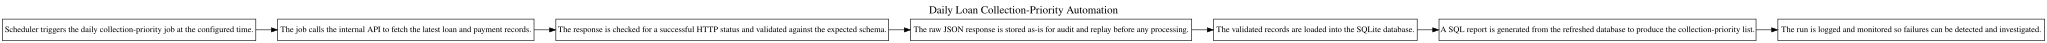

In [ ]:
# SQL DEVELOPER WORKSPACE
# TODO: Provide exactly seven ordered steps for the scheduled collection-priority workflow.
automation_steps = [
    "Scheduler triggers the daily collection-priority job at the configured time.",
    "The job calls the internal API to fetch the latest loan and payment records.",
    "The response is checked for a successful HTTP status and validated against the expected schema.",
    "The raw JSON response is stored as-is for audit and replay before any processing.",
    "The validated records are loaded into the SQLite database.",
    "A SQL report is generated from the refreshed database to produce the collection-priority list.",
    "The run is logged and monitored so failures can be detected and investigated."
]
validate_sequence('AUTO-FLOW', automation_steps, AUTO_FLOW_TERMS, 'Daily Loan Collection-Priority Automation')


### Expected Output - AUTO-FLOW

- Exactly seven steps in the required order.
- Required concepts appear in each corresponding step.
- A left-to-right workflow diagram renders after validation.

**Hint:** Keep each step concise and operational.

## AUTO-REPORT - Daily Collection-Priority Report

**Stakeholder:** Collections Operations Lead

**Business requirement:** Produce a scheduled **top-20 instalment-level** report of due instalments with the highest outstanding amount. Include the instalment identifier, due date, customer, branch, DPD, delinquency stage, and latest collection-action date for that same instalment.

**Tables to use:** `repayment_schedule`, `loans`, `customers`, `branches`, `payments`, `collection_actions`.

**How to approach:** Aggregate successful payment value and latest collection action by `(loan_id, installment_no)`, join them to due instalments, calculate outstanding amount and DPD as of `2026-08-01`, derive delinquency stage, then sort by outstanding amount descending (with deterministic tie-breakers) and use `LIMIT 20`.


In [ ]:
# SQL DEVELOPER WORKSPACE
# TODO: Write the scheduled collection-priority SQL report.
auto_report_sql = '''
WITH paid AS (
  SELECT loan_id, installment_no, SUM(amount) AS paid_amount
  FROM payments WHERE payment_status = 'SUCCESS'
  GROUP BY loan_id, installment_no
),
latest_action AS (
  SELECT loan_id, installment_no, MAX(action_date) AS latest_collection_action
  FROM collection_actions GROUP BY loan_id, installment_no
)
SELECT rs.loan_id, rs.installment_no, rs.due_date, c.customer_name, b.branch_name,
       ROUND(rs.due_amount - COALESCE(p.paid_amount, 0), 2) AS outstanding_amount,
       CAST(julianday('2026-08-01') - julianday(rs.due_date) AS INTEGER) AS days_past_due,
       CASE
         WHEN CAST(julianday('2026-08-01') - julianday(rs.due_date) AS INTEGER) > 90 THEN 'DPD_90_PLUS'
         WHEN CAST(julianday('2026-08-01') - julianday(rs.due_date) AS INTEGER) > 60 THEN 'DPD_61_90'
         WHEN CAST(julianday('2026-08-01') - julianday(rs.due_date) AS INTEGER) > 30 THEN 'DPD_31_60'
         WHEN CAST(julianday('2026-08-01') - julianday(rs.due_date) AS INTEGER) > 0 THEN 'DPD_1_30'
         ELSE 'CURRENT'
       END AS delinquency_stage,
       la.latest_collection_action
FROM repayment_schedule rs
JOIN loans l ON rs.loan_id = l.loan_id
JOIN customers c ON l.customer_id = c.customer_id
JOIN branches b ON l.branch_id = b.branch_id
LEFT JOIN paid p ON rs.loan_id = p.loan_id AND rs.installment_no = p.installment_no
LEFT JOIN latest_action la ON rs.loan_id = la.loan_id AND rs.installment_no = la.installment_no
WHERE rs.due_date < '2026-08-01' AND COALESCE(p.paid_amount, 0) < rs.due_amount
ORDER BY outstanding_amount DESC, days_past_due DESC, rs.loan_id, rs.installment_no
LIMIT 20;
'''
validate_sql('AUTO-REPORT', auto_report_sql)

AUTO-REPORT: Passed - columns=True; rows=20/20; key_result=True


,loan_id,installment_no,due_date,customer_name,branch_name,outstanding_amount,days_past_due,delinquency_stage,latest_collection_action
0,L000385,1,2026-01-10,Aarav Kapoor 193,Chennai Retail Lending 2,"698,128.75",203,DPD_90_PLUS,2026-07-08
1,L000338,1,2026-01-23,Dev Kapoor 222,Delhi Retail Lending 2,"698,128.75",190,DPD_90_PLUS,None
2,L000359,1,2026-01-24,Varun Agarwal 036,Chennai Retail Lending 1,"523,596.56",189,DPD_90_PLUS,2026-07-25
3,L000359,6,2026-06-24,Varun Agarwal 036,Chennai Retail Lending 1,"523,596.56",38,DPD_31_60,2026-07-14
4,L000265,7,2026-07-10,Manav Agarwal 152,Bhubaneswar Retail Lending 1,"523,596.56",22,DPD_1_30,2026-07-24
5,L000084,1,2026-01-09,Rohan Agarwal 221,Mumbai Retail Lending 2,"475,315.77",204,DPD_90_PLUS,2026-07-27
6,L000084,5,2026-05-09,Rohan Agarwal 221,Mumbai Retail Lending 2,"475,315.77",84,DPD_61_90,None
7,L000084,6,2026-06-09,Rohan Agarwal 221,Mumbai Retail Lending 2,"475,315.77",53,DPD_31_60,None
8,L000239,6,2026-06-24,Bhavna Bose 276,Mumbai Retail Lending 2,"475,315.77",38,DPD_31_60,None
9,L000073,5,2026-05-18,Varun Agarwal 279,Pune Retail Lending 3,"356,800.11",75,DPD_61_90,2026-07-03


,loan_id,installment_no,due_date,customer_name,branch_name,outstanding_amount,days_past_due,delinquency_stage,latest_collection_action
0,L000385,1,2026-01-10,Aarav Kapoor 193,Chennai Retail Lending 2,"698,128.75",203,DPD_90_PLUS,2026-07-08
1,L000338,1,2026-01-23,Dev Kapoor 222,Delhi Retail Lending 2,"698,128.75",190,DPD_90_PLUS,None
2,L000359,1,2026-01-24,Varun Agarwal 036,Chennai Retail Lending 1,"523,596.56",189,DPD_90_PLUS,2026-07-25
3,L000359,6,2026-06-24,Varun Agarwal 036,Chennai Retail Lending 1,"523,596.56",38,DPD_31_60,2026-07-14
4,L000265,7,2026-07-10,Manav Agarwal 152,Bhubaneswar Retail Lending 1,"523,596.56",22,DPD_1_30,2026-07-24
5,L000084,1,2026-01-09,Rohan Agarwal 221,Mumbai Retail Lending 2,"475,315.77",204,DPD_90_PLUS,2026-07-27
6,L000084,5,2026-05-09,Rohan Agarwal 221,Mumbai Retail Lending 2,"475,315.77",84,DPD_61_90,None
7,L000084,6,2026-06-09,Rohan Agarwal 221,Mumbai Retail Lending 2,"475,315.77",53,DPD_31_60,None
8,L000239,6,2026-06-24,Bhavna Bose 276,Mumbai Retail Lending 2,"475,315.77",38,DPD_31_60,None
9,L000073,5,2026-05-18,Varun Agarwal 279,Pune Retail Lending 3,"356,800.11",75,DPD_61_90,2026-07-03


#### Expected Output - AUTO-REPORT

| Column | Requirement |
|---|---|
| `loan_id` | Required output column |
| `installment_no` | Required output column |
| `due_date` | Required output column |
| `customer_name` | Required output column |
| `branch_name` | Required output column |
| `outstanding_amount` | Required output column |
| `days_past_due` | Required output column |
| `delinquency_stage` | Required output column |
| `latest_collection_action` | Required output column |

- **Expected row count:** `20`
- **Stable first-row check:** `loan_id = L000385`, `installment_no = 1`, `due_date = 2026-01-10`, `outstanding_amount = 698128.75`
- **Hint:** standard CTEs, LEFT JOIN, COALESCE, CASE, ORDER BY, LIMIT
- Validation checks exact column order, row count, stable first-row values, and overall status.


## AUTO-CRON - Cron Expressions

Fill the four exact five-field schedules: daily at 8 AM/12 PM/4 PM; weekdays at 5 PM; daily at midnight; Sundays at 2 AM.

In [ ]:
# SQL DEVELOPER WORKSPACE
# TODO: Fill all four five-field cron expressions.
cron_answers = {
    'three_times_daily': '0 8,12,16 * * *',   # minute 0, hours 8/12/16 (8am, 12pm, 4pm), every day
    'weekday_5pm': '0 17 * * 1-5',             # minute 0, hour 17 (5pm), Mon(1)-Fri(5) only
    'daily_midnight': '0 0 * * *',             # minute 0, hour 0 — midnight, every day
    'sunday_2am': '0 2 * * 0'                  # minute 0, hour 2, day-of-week 0 = Sunday
}
validate_cron(cron_answers)

AUTO-CRON: Passed - all four exact cron expressions validated.


,scenario,expression,status
0,three_times_daily,"0 8,12,16 * * *",Passed
1,weekday_5pm,0 17 * * 1-5,Passed
2,daily_midnight,0 0 * * *,Passed
3,sunday_2am,0 2 * * 0,Passed


### Expected Output - AUTO-CRON

| Scenario | Expected expression |
|---|---|
| Daily at 8 AM, 12 PM, 4 PM | `0 8,12,16 * * *` |
| Every weekday at 5 PM | `0 17 * * 1-5` |
| Every day at midnight | `0 0 * * *` |
| Every Sunday at 2 AM | `0 2 * * 0` |

**Hint:** Each cron expression has exactly five fields.

# 7. Engineering Practices

Represent professional collaboration and safe-change workflows as ordered, validated sequences rather than requiring repository or deployment execution.

## ENG-GIT - Git Collaboration Workflow

Provide the eight ordered collaboration steps from requirement review through approved merge.

ENG-GIT: Passed - exact 8-step sequence and required concepts validated.


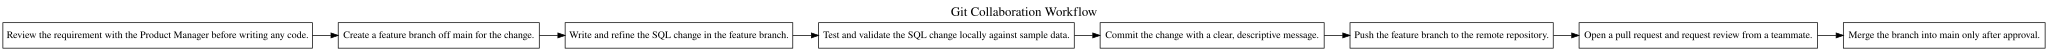

In [ ]:
# SQL DEVELOPER WORKSPACE
# TODO: Provide exactly eight ordered Git collaboration steps.
git_steps = [
    "Review the requirement with the Product Manager before writing any code.",
    "Create a feature branch off main for the change.",
    "Write and refine the SQL change in the feature branch.",
    "Test and validate the SQL change locally against sample data.",
    "Commit the change with a clear, descriptive message.",
    "Push the feature branch to the remote repository.",
    "Open a pull request and request review from a teammate.",
    "Merge the branch into main only after approval."
]
validate_sequence('ENG-GIT', git_steps, GIT_TERMS, 'Git Collaboration Workflow')

### Expected Output - ENG-GIT

- Exactly eight ordered steps.
- Requirement, feature branch, SQL change, test/validation, commit, push, pull request/review, and approved merge all appear in order.
- A workflow diagram renders after validation.

## ENG-CHANGE - Safe Database-Change Workflow

Provide the eight ordered database-change steps from requirement understanding through monitoring and rollback-on-failure.

ENG-CHANGE: Passed - exact 8-step sequence and required concepts validated.


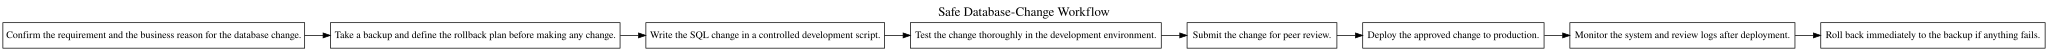

In [ ]:
# SQL DEVELOPER WORKSPACE
# TODO: Provide exactly eight ordered safe database-change steps.
change_steps = [
    "Confirm the requirement and the business reason for the database change.",
    "Take a backup and define the rollback plan before making any change.",
    "Write the SQL change in a controlled development script.",
    "Test the change thoroughly in the development environment.",
    "Submit the change for peer review.",
    "Deploy the approved change to production.",
    "Monitor the system and review logs after deployment.",
    "Roll back immediately to the backup if anything fails."
]
validate_sequence('ENG-CHANGE', change_steps, CHANGE_TERMS, 'Safe Database-Change Workflow')


### Expected Output - ENG-CHANGE

- Exactly eight ordered steps.
- Backup/rollback plan, SQL change, development testing, peer review, approved deployment, monitoring, and rollback-if-failed appear in order.
- A workflow diagram renders after validation.

# 8. Progress Check

The dashboard below lists every required activity and the current validation status.

In [ ]:
progress_check()


,activity_id,status
0,ER-1,Passed
1,API-Q1,Passed
2,API-Q2,Passed
3,API-Q3,Passed
4,API-Q4,Passed
5,API-Q5,Passed
6,Q1,Passed
7,Q2,Passed
8,Q3,Passed
9,Q4,Passed


Passed activities: 26/26


,activity_id,status
0,ER-1,Passed
1,API-Q1,Passed
2,API-Q2,Passed
3,API-Q3,Passed
4,API-Q4,Passed
5,API-Q5,Passed
6,Q1,Passed
7,Q2,Passed
8,Q3,Passed
9,Q4,Passed
